# Análisis de resultados · baseline LoRA

Lee los zips de una carpeta (los que deja `correr_variantes.sh` en `resultados/`, o cualquier zip de corrida del notebook de entrenamiento) y muestra, por corrida:

1. Un resumen de la corrida y las curvas de pérdida de entrenamiento y de validación (dev), para ver desde cuándo hay sobreajuste.
2. La comparación de métricas entre dev y test, en global y por clase.
3. Las matrices de confusión de dev y test.

Al final, una tabla con todas las corridas y el ranking por macro-F1 de test.

**Entrada:** la carpeta con los zips, en `CARPETA_RESULTADOS` (celda 1) o en la variable de entorno del mismo nombre. Por defecto, `resultados`.

**Requisitos:** `pip install pandas matplotlib jinja2` (jinja2 es lo que usa pandas para mostrar las tablas con título).

In [2]:
# @title 1 · Librerías y parámetros
import json
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

CARPETA_RESULTADOS = Path(os.environ.get("CARPETA_RESULTADOS", "resultados"))
VENTANA_SUAVIZADO = 5      # puntos del registro de entrenamiento (uno cada LOG_CADA pasos) para la media móvil
GUARDAR = os.environ.get("GUARDAR", "0") == "1"   # 1: guarda figuras (PNG) y tablas (CSV) en <carpeta>/analisis/

# Mismo orden que ETIQUETAS en el notebook de entrenamiento: son los índices de filas y columnas de la matriz de confusión.
ETIQUETAS = ["Background", "Uses", "Comparison", "Extends", "Motivation",
             "Future Work", "Evidence", "Originator", "Further Reading"]

# Colores: cada conjunto tiene siempre el mismo color en todas las figuras (paleta validada para daltonismo).
SUPERFICIE, TINTA, TINTA_2, TENUE, REJILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
COLOR = {"train": "#2a78d6", "dev": "#eb6834", "test": "#1baf7a"}
SECUENCIAL = LinearSegmentedColormap.from_list(
    "azul", ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.linewidth": 1, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "axes.axisbelow": True, "legend.frameon": False, "legend.labelcolor": TINTA_2, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round", "figure.dpi": 110,
})

In [3]:
# @title 2 · Lectura de los zips
def leer_zip(ruta: Path) -> dict:
    """Lee los JSON de una corrida directamente del zip, sin descomprimirlo, saltando la carpeta del adaptador.

    Devuelve {nombre sin .json: contenido}, por ejemplo {"config": {...}, "metricas_dev": {...}}.
    """
    datos = {}
    with zipfile.ZipFile(ruta) as z:
        for miembro in z.namelist():
            partes = Path(miembro).parts
            if miembro.endswith(".json") and "adaptador" not in partes[:-1]:
                with z.open(miembro) as f:
                    datos[Path(miembro).stem] = json.load(f)
    return datos


def cargar_corridas(carpeta: Path) -> list[dict]:
    """Lee todos los zips de la carpeta y devuelve una lista de corridas ordenada por nombre.

    Salta los zips que no son de una corrida (sin resumen.json o config.json) y los duplicados: si dos zips
    tienen la misma corrida (por ejemplo, ultima_corrida.zip y su copia con nombre), se queda con el que se
    llama como la corrida.
    """
    zips = sorted(carpeta.glob("*.zip"))
    if not zips:
        raise FileNotFoundError(f"No hay zips en {carpeta.resolve()}. Define CARPETA_RESULTADOS.")
    por_nombre = {}
    for ruta in zips:
        try:
            datos = leer_zip(ruta)
        except (zipfile.BadZipFile, json.JSONDecodeError) as e:
            print(f"Salto {ruta.name}: no se pudo leer ({type(e).__name__}).")
            continue
        if "resumen" not in datos or "config" not in datos:
            print(f"Salto {ruta.name}: no tiene resumen.json o config.json.")
            continue
        nombre = datos["resumen"].get("corrida") or datos["config"].get("nombre_corrida") or ruta.stem
        corrida = {"nombre": nombre, "zip": ruta.name,
                   "titulo": nombre if ruta.stem == nombre else f"{nombre} ({ruta.name})", **datos}
        previa = por_nombre.get(nombre)
        if previa is not None:
            descartada = corrida if Path(previa["zip"]).stem == nombre else previa
            print(f"Salto {descartada['zip']}: repite la corrida {nombre}.")
            if descartada is previa:
                por_nombre[nombre] = corrida
            continue
        por_nombre[nombre] = corrida
    return [por_nombre[n] for n in sorted(por_nombre)]


def pasos_por_epoca(c: dict) -> float | None:
    """Pasos de optimizador por época de la corrida, para poner las curvas en épocas. None si no se puede saber."""
    cfg, sel = c["config"], c["resumen"].get("seleccion", {})
    if not cfg.get("max_pasos") and sel.get("pasos_planeados") and cfg.get("epocas"):
        return sel["pasos_planeados"] / cfg["epocas"]
    evals = c.get("evaluaciones_dev") or []
    fin_epoca_1 = [e["paso"] for e in evals if e.get("epoca") == 1]
    if fin_epoca_1 and any(e.get("epoca", 1) > 1 for e in evals):
        return float(max(fin_epoca_1))   # la última evaluación de cada época cae en su último paso
    return None

In [4]:
# @title 3 · Tablas
def mostrar(df: pd.DataFrame, titulo: str, decimales: int = 3, formatos: dict | None = None) -> None:
    """Muestra una tabla con su título (el nombre de la corrida). Sin jinja2, imprime el título y la tabla simple.

    `formatos` fija el formato de columnas concretas, por ejemplo {"lr": "{:.0e}"} para que 1e-4 no se vea como 0.000.
    """
    formatos = formatos or {}
    try:
        estilo = df.style.set_caption(titulo).format(precision=decimales, na_rep="—")
        if formatos:   # solo las columnas indicadas; un dict vacío reformatearía todas
            estilo = estilo.format(formatos, na_rep="—")
        estilo = (estilo.set_table_styles([{"selector": "caption", "props": "caption-side: top; text-align: left; "
                                      "font-weight: bold; font-size: 1.05em; color: #0b0b0b; padding: 6px 0;"}]))
        display(estilo)
    except ImportError:
        print(f"\n{titulo}")
        simple = df.round(decimales)
        for columna, formato in formatos.items():
            simple[columna] = df[columna].map(lambda v: formato.format(v) if pd.notna(v) else "—")
        display(simple)


def suavizar(serie: pd.Series) -> pd.Series:
    """Media móvil de la pérdida de entrenamiento (el registro es ruidoso porque cada punto es una ventana corta)."""
    return serie.rolling(VENTANA_SUAVIZADO, min_periods=1).mean()


def tabla_resumen(c: dict) -> pd.DataFrame:
    """Datos clave de la corrida y de su curva de pérdida en dev, como tabla campo → valor."""
    cfg, res = c["config"], c["resumen"]
    sel, ent = res.get("seleccion", {}), res.get("entrenamiento", {})
    spe = pasos_por_epoca(c)
    epoca = (lambda paso: f"{paso / spe:.1f}") if spe else (lambda paso: f"paso {paso}")
    filas = {
        "modelo": cfg.get("modelo"), "variante LoRA": cfg.get("lora_tipo"), "configuración": cfg.get("configuracion"),
        "lr": cfg.get("lr"), "scheduler": cfg.get("scheduler", "linear"), "épocas planeadas": cfg.get("epocas"),
        "lote efectivo": cfg.get("batch", 0) * cfg.get("acumulacion", 1),
        "época del mejor macro-F1 dev": epoca(sel["mejor_paso"]) if sel.get("mejor_paso") else None,
        "pasos entrenados / planeados": f"{sel.get('pasos_entrenados', '?')} / {sel.get('pasos_planeados', '?')}",
        "parada temprana": {True: "sí", False: "no"}.get(sel.get("parada_temprana"), "—"),
    }
    evals = pd.DataFrame(c.get("evaluaciones_dev") or [])
    if not evals.empty and "perdida" in evals:
        i_min = evals["perdida"].idxmin()
        minima, final = evals.loc[i_min, "perdida"], evals["perdida"].iloc[-1]
        filas |= {"época de la pérdida dev mínima": epoca(evals.loc[i_min, "paso"]),
                  "pérdida dev mínima": f"{minima:.3f}", "pérdida dev al final": f"{final:.3f}",
                  "subida de la pérdida dev desde el mínimo": f"{final / minima - 1:+.0%}"}
    filas |= {"minutos de entrenamiento": f"{ent['segundos'] / 60:.1f}" if ent.get("segundos") else None,
              "memoria pico (GB)": f"{ent['memoria_pico_gb']:.1f}" if ent.get("memoria_pico_gb") else None,
              "GPU": res.get("hardware", {}).get("gpu"),
              "parámetros entrenables": f"{res['lora']['porcentaje']:.2f} %" if "lora" in res else None}
    return pd.DataFrame({"valor": {k: ("—" if v is None else str(v)) for k, v in filas.items()}})


def macro_f1_comunes(c: dict) -> tuple[float | None, float | None, list[str]]:
    """Macro-F1 de dev y de test promediando solo las clases que tienen ejemplos en ambos splits.

    Dev tiene clases que test no (Further Reading, Future Work), así que el macro-F1 de cada split promedia clases
    distintas. El F1 de una clase no depende de las demás, así que basta con promediar las comunes.
    """
    dev, test = c.get("metricas_dev"), c.get("metricas_test")
    if not dev or not test:
        return None, None, []
    comunes = [e for e in ETIQUETAS if e in dev["por_clase"] and e in test["por_clase"]]
    media = lambda m: float(np.mean([m["por_clase"][e]["f1"] for e in comunes])) if comunes else None
    return media(dev), media(test), comunes


def tabla_dev_test(c: dict) -> pd.DataFrame:
    """Métricas globales de dev y test lado a lado, con el macro-F1 recalculado sobre las clases comunes."""
    f1_dev_c, f1_test_c, comunes = macro_f1_comunes(c)
    columnas = {}
    for split, f1_comun in (("dev", f1_dev_c), ("test", f1_test_c)):
        m = c.get(f"metricas_{split}")
        if not m:
            continue
        ic = m.get("macro_f1_ic95") or [None, None]
        columnas[split] = {
            "macro-F1 (clases de cada split)": m["macro_f1"], "IC95 inferior": ic[0], "IC95 superior": ic[1],
            f"macro-F1 (las {len(comunes)} clases comunes)": f1_comun,
            "macro-F1 solo multicite": m.get("por_fuente", {}).get("multicite", {}).get("macro_f1"),
            "accuracy": m["accuracy"], "ECE": m.get("ece"), "n": m["n"],
            "clases evaluadas": len(m.get("clases_evaluadas", [])),
        }
    tabla = pd.DataFrame(columnas).astype(object)
    for fila in ("n", "clases evaluadas"):   # enteros: sin decimales en la tabla
        tabla.loc[fila] = tabla.loc[fila].map(lambda v: int(v) if pd.notna(v) else v)
    return tabla


def tabla_por_clase(c: dict) -> pd.DataFrame:
    """Precisión, recall, F1 y soporte por clase en dev y test (columnas agrupadas por split)."""
    partes = {}
    for split in ("dev", "test"):
        m = c.get(f"metricas_{split}")
        if m:
            df = pd.DataFrame(m["por_clase"]).T.rename(columns={"precision": "P", "recall": "R", "f1": "F1", "soporte": "n"})
            df["n"] = df["n"].astype("Int64")
            partes[split] = df[["P", "R", "F1", "n"]]
    tabla = pd.concat(partes, axis=1)
    return tabla.reindex([e for e in ETIQUETAS if e in tabla.index])

In [5]:
# @title 4 · Gráficas
def guardar_figura(fig, c: dict, sufijo: str) -> None:
    """Si GUARDAR=1, guarda la figura como PNG en <carpeta>/analisis/<corrida>_<sufijo>.png."""
    if GUARDAR:
        destino = CARPETA_RESULTADOS / "analisis"
        destino.mkdir(exist_ok=True)
        fig.savefig(destino / f"{c['nombre']}_{sufijo}.png", dpi=160, bbox_inches="tight")


def graficar_perdidas(c: dict) -> None:
    """Pérdida de entrenamiento y de dev en el mismo eje, y debajo el macro-F1 de dev, con el mejor punto marcado.

    Si la pérdida de dev sube mientras la de entrenamiento sigue bajando, el modelo está sobreajustando; el early
    stopping se queda con el punto de mejor macro-F1 de dev (línea vertical).
    """
    registro = pd.DataFrame(c.get("registro_entrenamiento") or [])
    evals = pd.DataFrame(c.get("evaluaciones_dev") or [])
    if registro.empty and evals.empty:
        print("Sin registro de entrenamiento ni evaluaciones de dev: no hay curvas que graficar.")
        return
    spe = pasos_por_epoca(c)
    eje = (lambda pasos: pasos / spe) if spe else (lambda pasos: pasos)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]},
                                   constrained_layout=True)
    fig.suptitle(c["titulo"], x=0.01, ha="left", fontsize=12, color=TINTA)

    finales = {}
    if not registro.empty:
        x = eje(registro["paso"])
        ax1.plot(x, registro["perdida"], color=COLOR["train"], lw=1, alpha=0.3)
        suave = suavizar(registro["perdida"])
        ax1.plot(x, suave, color=COLOR["train"], label=f"entrenamiento (media móvil de {VENTANA_SUAVIZADO} registros)")
        finales["entrenamiento"] = (x.iloc[-1], suave.iloc[-1])
    if not evals.empty and "perdida" in evals:
        x = eje(evals["paso"])
        ax1.plot(x, evals["perdida"], color=COLOR["dev"], marker="o", markersize=8, markeredgecolor=SUPERFICIE,
                 markeredgewidth=2, label="validación (dev)")
        finales["dev"] = (x.iloc[-1], evals["perdida"].iloc[-1])
    ax1.set_ylabel("pérdida (entropía cruzada)")
    ax1.set_ylim(bottom=0)
    ax1.legend(loc="upper right")
    # Etiquetas directas al final de cada curva, solo si no se pisan
    if len(finales) == 2:
        (_, y1), (_, y2) = finales.values()
        if abs(y1 - y2) > 0.06 * ax1.get_ylim()[1]:
            for texto, (xf, yf) in finales.items():
                ax1.annotate(f"{texto} {yf:.2f}", (xf, yf), xytext=(6, 0), textcoords="offset points",
                             va="center", fontsize=9, color=TINTA_2)

    titulo_f1 = "macro-F1 de dev"
    if not evals.empty:
        x = eje(evals["paso"])
        ax2.plot(x, evals["macro_f1"], color=COLOR["dev"], marker="o", markersize=8, markeredgecolor=SUPERFICIE,
                 markeredgewidth=2)
        ax2.set_ylabel("macro-F1")
    mejor = c["resumen"].get("seleccion", {}).get("mejor_paso")
    if mejor:
        for ax in (ax1, ax2):
            ax.axvline(eje(mejor), color=TENUE, lw=1)
        f1_mejor = c["resumen"]["seleccion"].get("mejor_macro_f1_dev")
        if f1_mejor is not None:
            ax2.annotate(f"mejor: {f1_mejor:.3f}", (eje(mejor), f1_mejor), xytext=(8, -14),
                         textcoords="offset points", fontsize=9, color=TINTA_2)
        test = c.get("metricas_test")
        if test:
            ax2.plot([eje(mejor)], [test["macro_f1"]], marker="D", markersize=8, color=COLOR["test"],
                     markeredgecolor=SUPERFICIE, markeredgewidth=2, linestyle="none")
            ax2.annotate(f"test: {test['macro_f1']:.3f}", (eje(mejor), test["macro_f1"]), xytext=(8, 0),
                         textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
            titulo_f1 += " (rombo: test con los pesos del mejor punto)"
    ax2.set_title(titulo_f1, fontsize=10, color=TINTA_2)
    ax1.set_title("pérdida de entrenamiento y de validación · línea vertical: punto elegido por el early stopping",
                  fontsize=10, color=TINTA_2)
    ax2.set_xlabel("época" if spe else "paso de optimizador")
    guardar_figura(fig, c, "perdidas")
    plt.show()


def graficar_f1_por_clase(c: dict, tabla: pd.DataFrame) -> None:
    """Barras horizontales con el F1 de cada clase en dev y en test. Las clases sin ejemplos en un split no tienen barra."""
    splits = [s for s in ("dev", "test") if s in tabla.columns.get_level_values(0)]
    clases = list(tabla.index)
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(clases) + 1.2), constrained_layout=True)
    alto = 0.8 / len(splits)
    for k, split in enumerate(splits):
        f1 = tabla[(split, "F1")]
        y = np.arange(len(clases)) + (k - (len(splits) - 1) / 2) * alto
        ax.barh(y, f1.fillna(0), height=alto, color=COLOR[split], edgecolor=SUPERFICIE, linewidth=2,
                label=split)
        for yi, valor in zip(y, f1):
            if valor == 0:   # una barra de largo 0 no se ve: se marca con su valor
                ax.annotate("0", (0, yi), xytext=(4, 0), textcoords="offset points", va="center",
                            fontsize=8.5, color=TINTA_2)
    etiquetas = [f"{e}" + ("" if all(pd.notna(tabla.loc[e, (s, "F1")]) for s in splits) else "  (solo "
                 + "/".join(s for s in splits if pd.notna(tabla.loc[e, (s, "F1")])) + ")") for e in clases]
    ax.set_yticks(np.arange(len(clases)), etiquetas)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("F1")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=len(splits))
    ax.set_title(f"{c['titulo']} · F1 por clase", fontsize=11)
    guardar_figura(fig, c, "f1_por_clase")
    plt.show()


def graficar_confusiones(c: dict) -> None:
    """Matrices de confusión de dev y test, solo con las clases que aparecen (en el gold o en las predicciones).

    El color es el porcentaje de cada fila (el recall de esa clase real); cada celda muestra el conteo y ese %.
    """
    splits = [s for s in ("dev", "test") if c.get(f"metricas_{s}")]
    if not splits:
        return
    fig, axes = plt.subplots(1, len(splits), figsize=(6.4 * len(splits), 5.6), constrained_layout=True, squeeze=False)
    fig.suptitle(f"{c['titulo']} · matrices de confusión", x=0.01, ha="left", fontsize=12, color=TINTA)
    for ax, split in zip(axes[0], splits):
        m = np.array(c[f"metricas_{split}"]["confusion"])
        presentes = [i for i in range(len(m)) if m[i].sum() > 0 or m[:, i].sum() > 0]
        sub = m[np.ix_(presentes, presentes)]
        totales = sub.sum(axis=1, keepdims=True)
        pct = np.divide(sub, totales, out=np.zeros(sub.shape), where=totales > 0)
        imagen = ax.imshow(pct, cmap=SECUENCIAL, vmin=0, vmax=1)
        for i in range(len(presentes)):
            for j in range(len(presentes)):
                if sub[i, j]:
                    ax.text(j, i, f"{sub[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=8.5,
                            color="#ffffff" if pct[i, j] > 0.55 else TINTA)
        nombres = [ETIQUETAS[i] for i in presentes]
        ax.set_xticks(range(len(presentes)), nombres, rotation=35, ha="right")
        ax.set_yticks(range(len(presentes)), [f"{n} ({t})" for n, t in zip(nombres, totales[:, 0])])
        # Separación de 2 px en el color de fondo entre celdas, en vez de bordes
        ax.set_xticks(np.arange(-0.5, len(presentes)), minor=True)
        ax.set_yticks(np.arange(-0.5, len(presentes)), minor=True)
        ax.grid(which="minor", color=SUPERFICIE, linewidth=2)
        ax.grid(which="major", visible=False)
        ax.tick_params(which="both", length=0)
        for lado in ax.spines.values():
            lado.set_visible(False)
        ax.set_xlabel("predicción")
        ax.set_ylabel("clase real (soporte)")
        ax.set_title(f"{split} · n = {c[f'metricas_{split}']['n']}", fontsize=10, color=TINTA_2)
    barra = fig.colorbar(imagen, ax=axes[0].tolist(), shrink=0.75, format=PercentFormatter(xmax=1, decimals=0))
    barra.set_label("% de la fila (recall de la clase real)", color=TINTA_2)
    barra.outline.set_visible(False)
    guardar_figura(fig, c, "confusion")
    plt.show()


def graficar_test_con_ic(tabla: pd.DataFrame) -> None:
    """macro-F1 de test de cada corrida con su intervalo de confianza del 95 %, ordenado de mayor a menor."""
    datos = tabla.dropna(subset=["macro-F1 test"]).sort_values("macro-F1 test")
    if datos.empty:
        return
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(datos) + 1.4), constrained_layout=True)
    y = np.arange(len(datos))
    ax.hlines(y, datos["IC95 test inf."], datos["IC95 test sup."], color=COLOR["test"], lw=2)
    ax.plot(datos["macro-F1 test"], y, "o", markersize=9, color=COLOR["test"], markeredgecolor=SUPERFICIE,
            markeredgewidth=2)
    ax.set_yticks(y, datos.index)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("macro-F1 de test (punto) e intervalo de confianza del 95 % (línea)")
    ax.set_title("macro-F1 de test por corrida · si los intervalos se solapan, la diferencia puede ser ruido", fontsize=11)
    if GUARDAR:
        destino = CARPETA_RESULTADOS / "analisis"
        destino.mkdir(exist_ok=True)
        fig.savefig(destino / "test_con_ic95.png", dpi=160, bbox_inches="tight")
    plt.show()

In [6]:
# @title 5 · Cargar las corridas
corridas = cargar_corridas(CARPETA_RESULTADOS)
print(f"{len(corridas)} corridas en {CARPETA_RESULTADOS.resolve()}")

12 corridas en /home/danpz/test_colab/resultados


## Por corrida

Para cada corrida: resumen, curvas de pérdida, métricas de dev frente a test y matrices de confusión.

- **Cómo leer las curvas:** si la pérdida de dev sube mientras la de entrenamiento sigue bajando, hay sobreajuste desde ese punto. El early stopping se queda con los pesos del mejor macro-F1 de dev (línea vertical), así que la evaluación final no usa los pesos sobreajustados.
- **Cómo comparar dev con test:** dev incluye Further Reading y Future Work, que test no tiene. Además, Further Reading viene entera de unarxive_mined y el modelo la acierta casi siempre por la fuente. Por eso el macro-F1 que se compara de verdad es el de las clases comunes. El de solo multicite también sirve, pero en dev sigue incluyendo Future Work.

### Qwen3-4B-Base_lora_A_lr1e-4

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,A
lr,0.0001
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,4.0
pasos entrenados / planeados,916 / 1128
parada temprana,sí


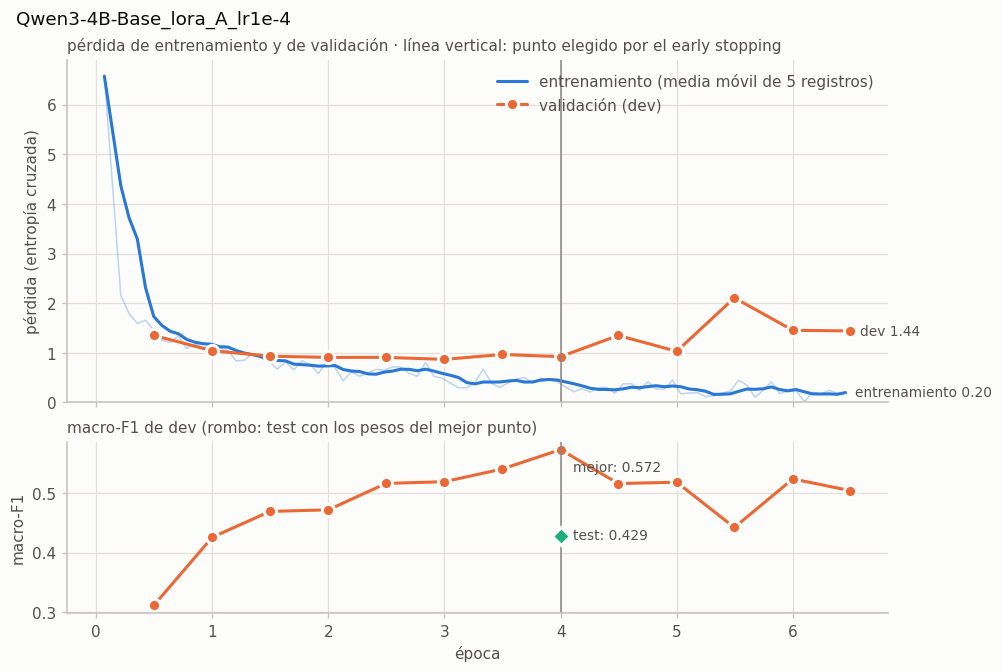

,dev,test
macro-F1 (clases de cada split),0.572,0.429
IC95 inferior,0.482,0.384
IC95 superior,0.653,0.472
macro-F1 (las 5 clases comunes),0.501,0.429
macro-F1 solo multicite,0.501,0.429
accuracy,0.692,0.613
ECE,0.105,0.155
n,491,486
clases evaluadas,7,5


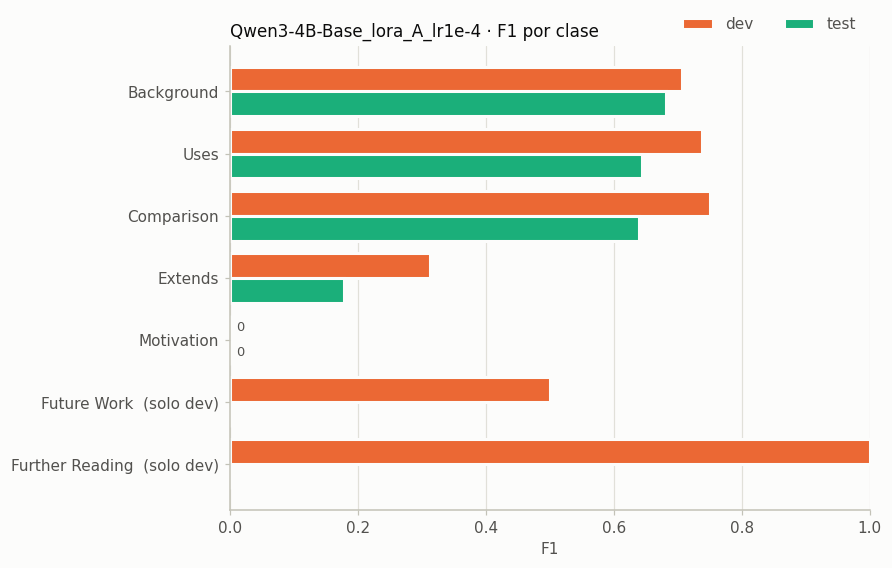

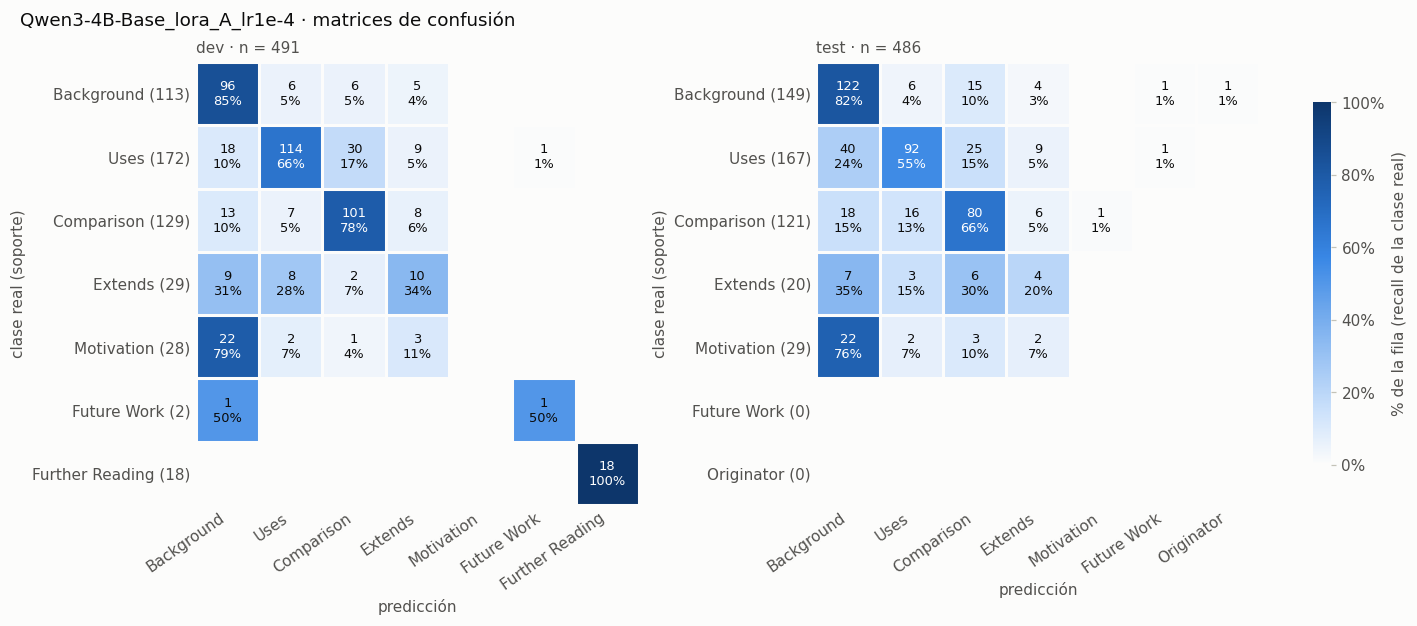

### Qwen3-4B-Base_lora_A_lr2e-4

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,A
lr,0.0002
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,3.0
pasos entrenados / planeados,775 / 1128
parada temprana,sí


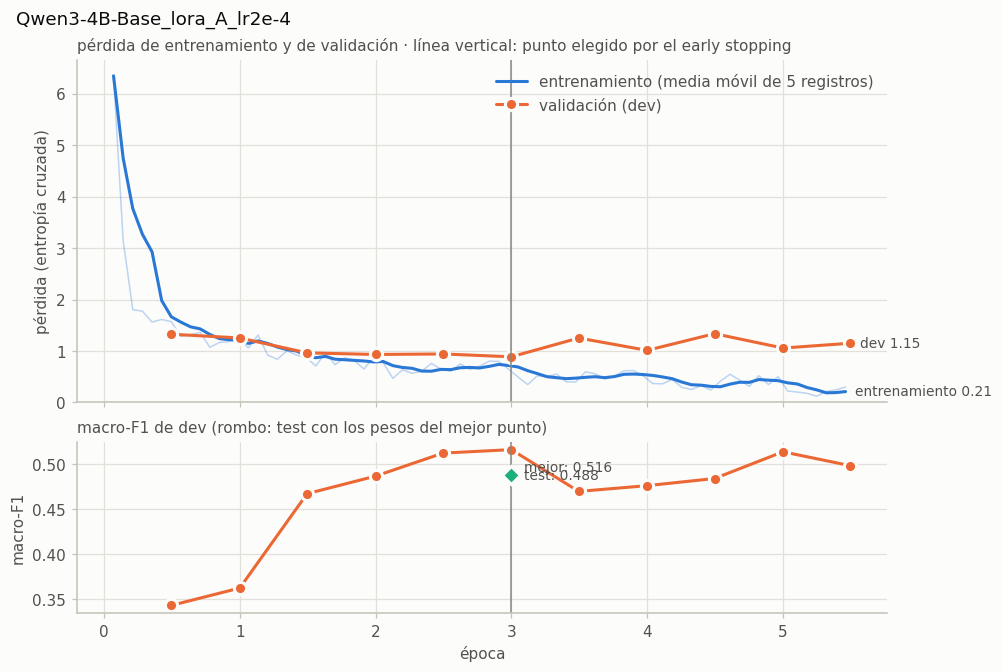

,dev,test
macro-F1 (clases de cada split),0.516,0.488
IC95 inferior,0.484,0.436
IC95 superior,0.614,0.533
macro-F1 (las 5 clases comunes),0.522,0.488
macro-F1 solo multicite,0.435,0.488
accuracy,0.701,0.654
ECE,0.065,0.082
n,491,486
clases evaluadas,7,5


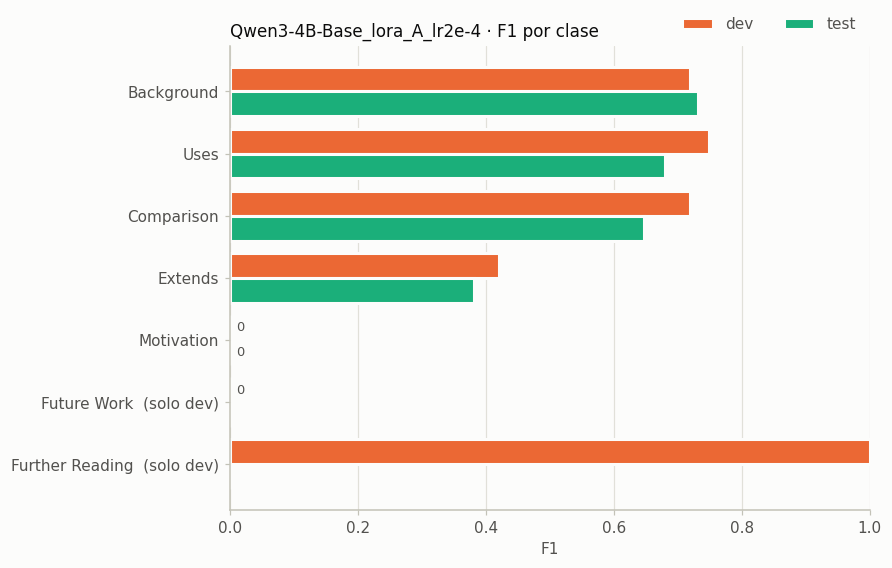

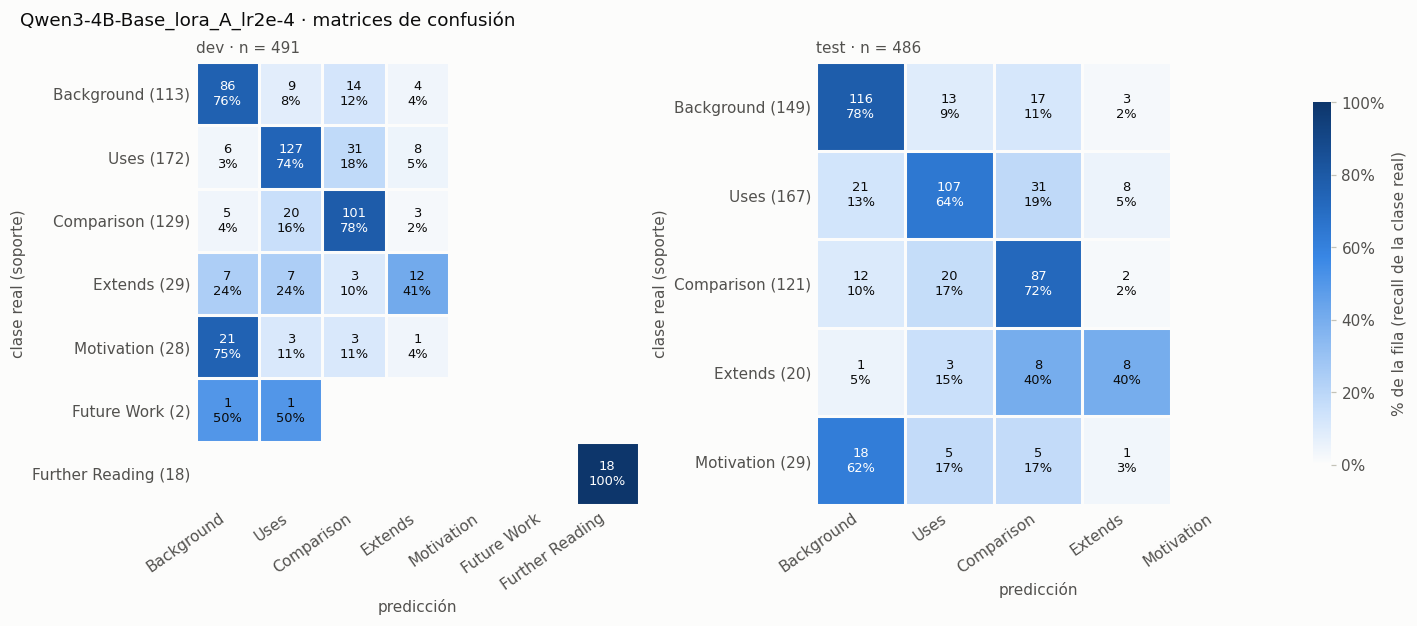

### Qwen3-4B-Base_lora_A_lr5e-5

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,A
lr,5e-05
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,5.0
pasos entrenados / planeados,1057 / 1128
parada temprana,sí


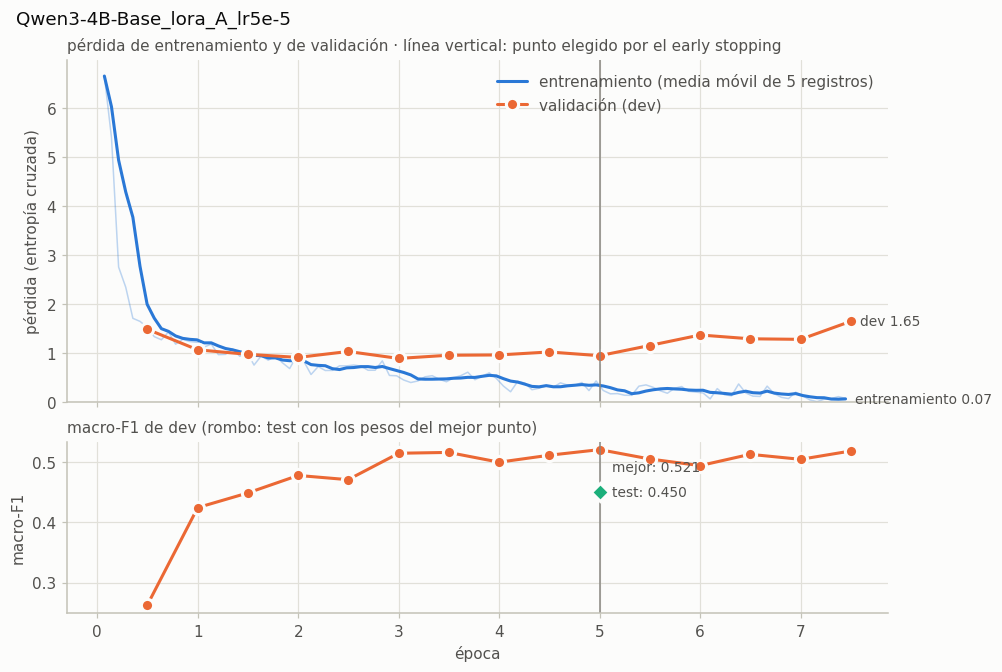

,dev,test
macro-F1 (clases de cada split),0.521,0.450
IC95 inferior,0.485,0.400
IC95 superior,0.625,0.498
macro-F1 (las 5 clases comunes),0.530,0.450
macro-F1 solo multicite,0.441,0.450
accuracy,0.692,0.615
ECE,0.128,0.156
n,491,486
clases evaluadas,7,5


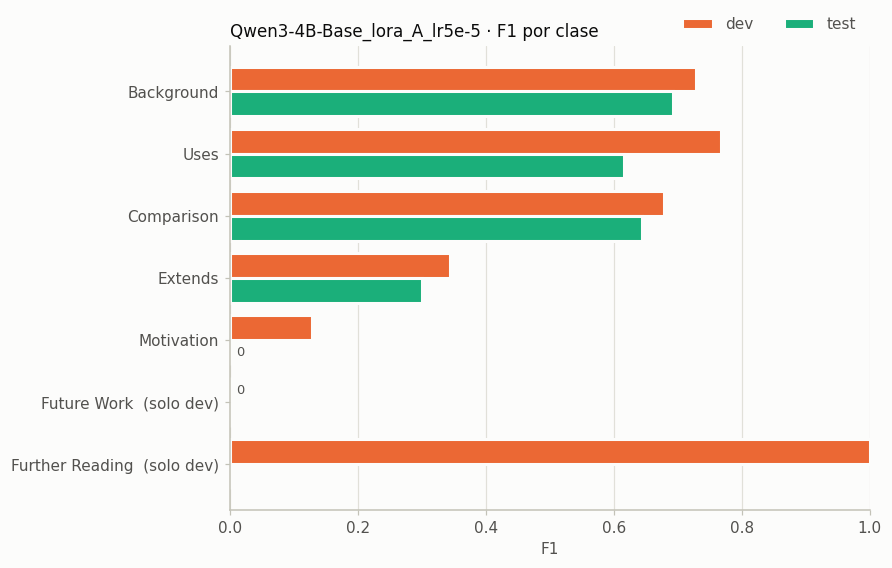

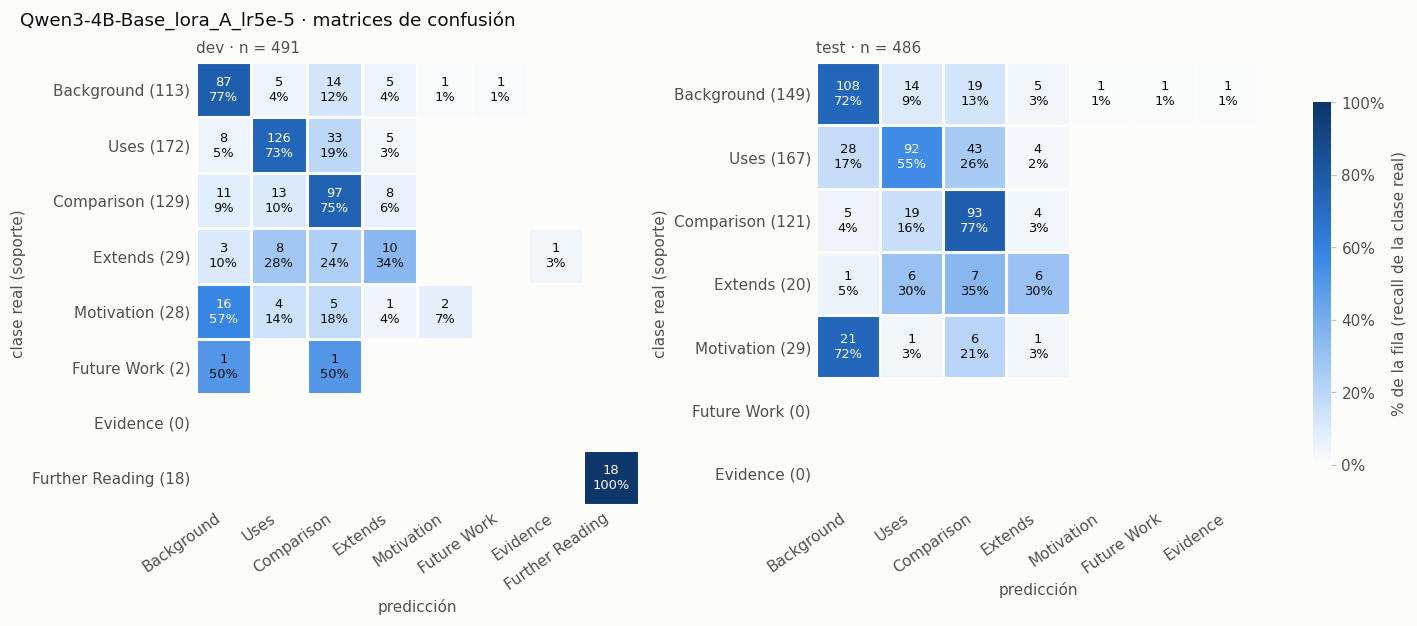

### Qwen3-4B-Base_lora_B_lr1e-4

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,4.0
pasos entrenados / planeados,916 / 1128
parada temprana,sí


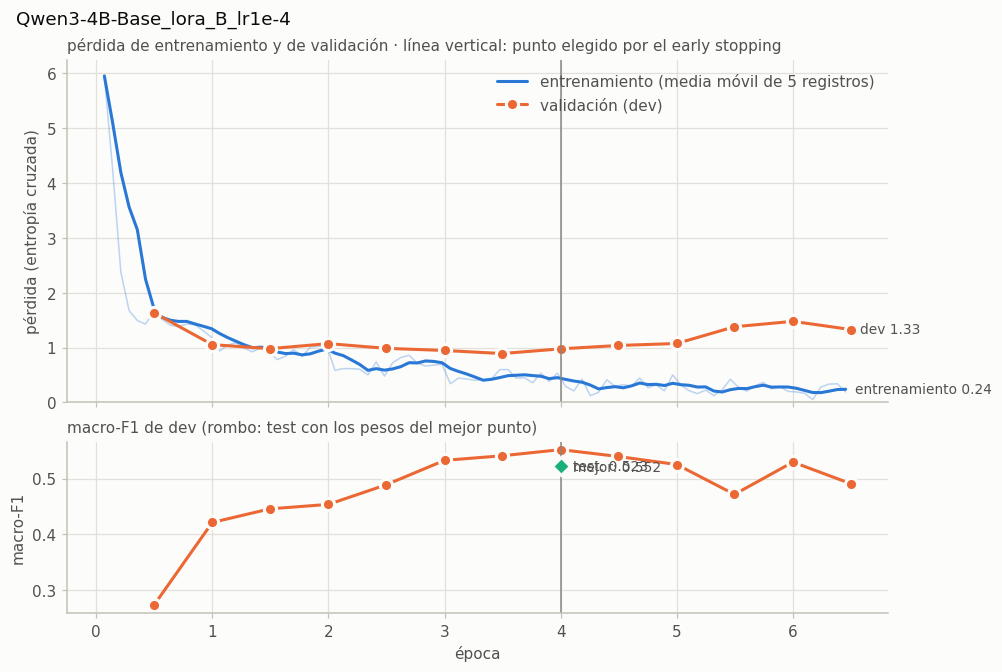

,dev,test
macro-F1 (clases de cada split),0.552,0.523
IC95 inferior,0.513,0.465
IC95 superior,0.668,0.577
macro-F1 (las 5 clases comunes),0.573,0.523
macro-F1 solo multicite,0.477,0.523
accuracy,0.676,0.597
ECE,0.076,0.113
n,491,486
clases evaluadas,7,5


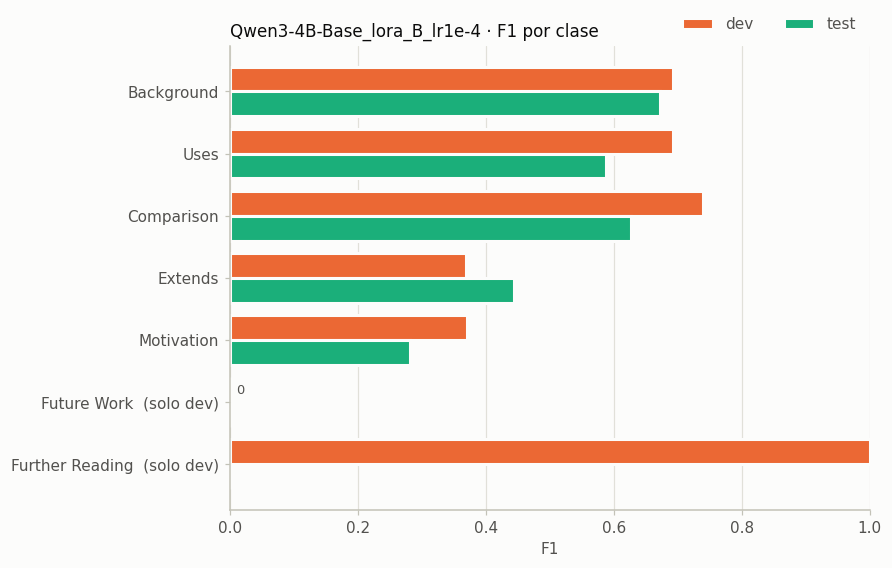

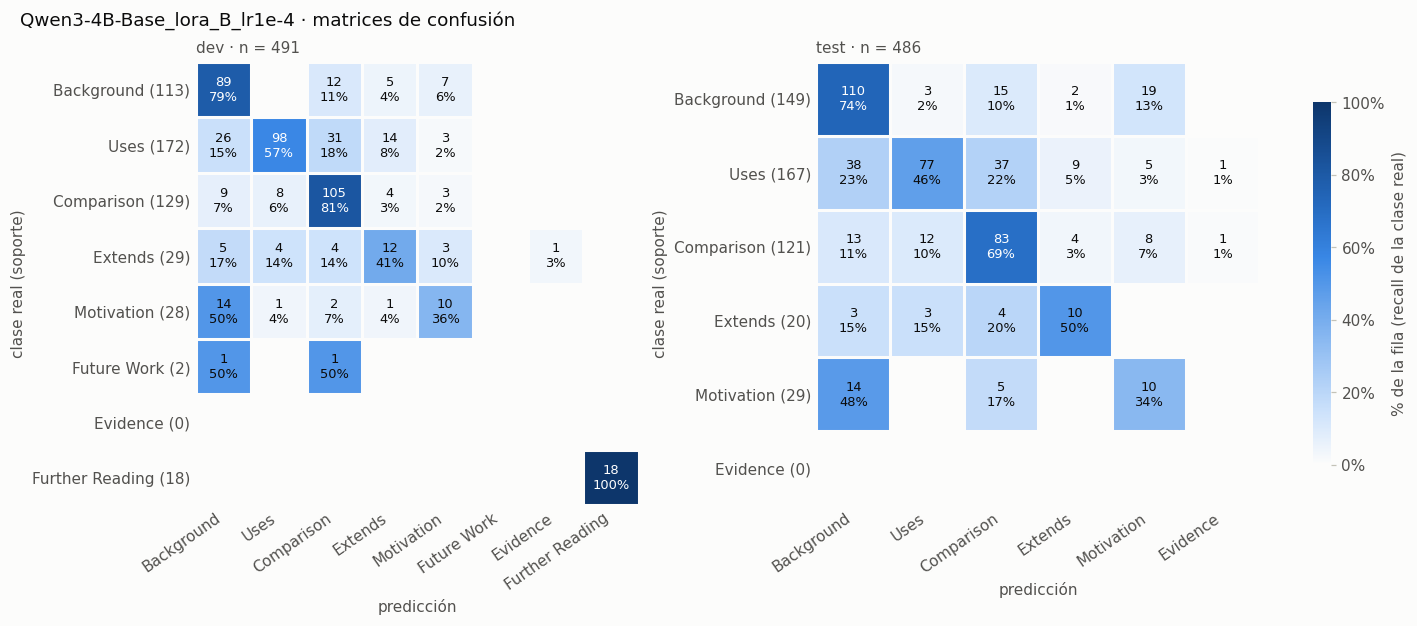

### Qwen3-4B-Base_lora_B_lr2e-4

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,B
lr,0.0002
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,4.5
pasos entrenados / planeados,987 / 1128
parada temprana,sí


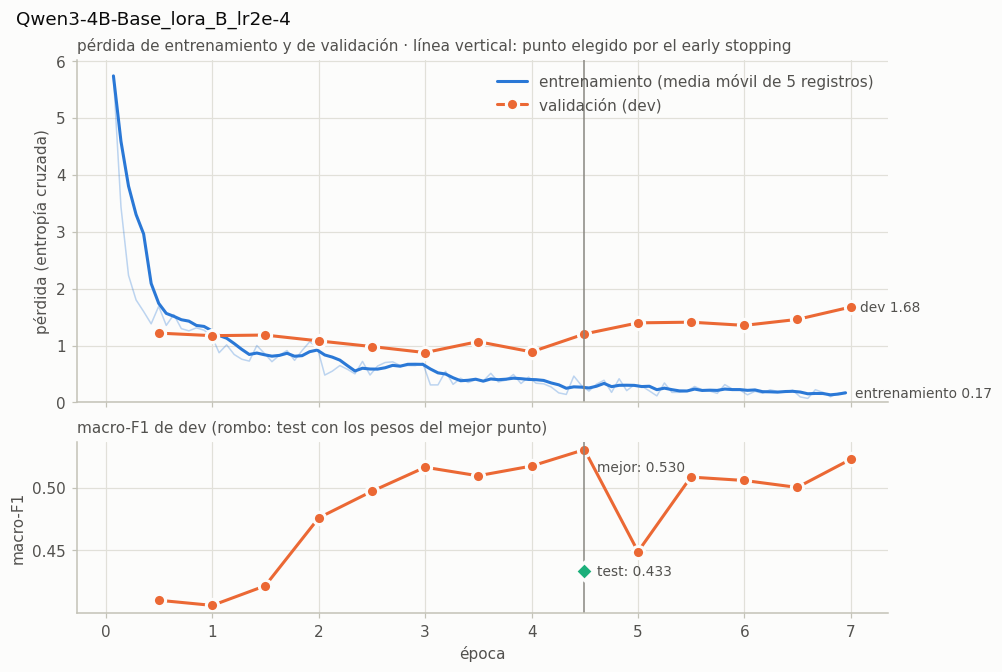

,dev,test
macro-F1 (clases de cada split),0.530,0.433
IC95 inferior,0.495,0.373
IC95 superior,0.636,0.493
macro-F1 (las 5 clases comunes),0.542,0.433
macro-F1 solo multicite,0.452,0.433
accuracy,0.699,0.553
ECE,0.167,0.252
n,491,486
clases evaluadas,7,5


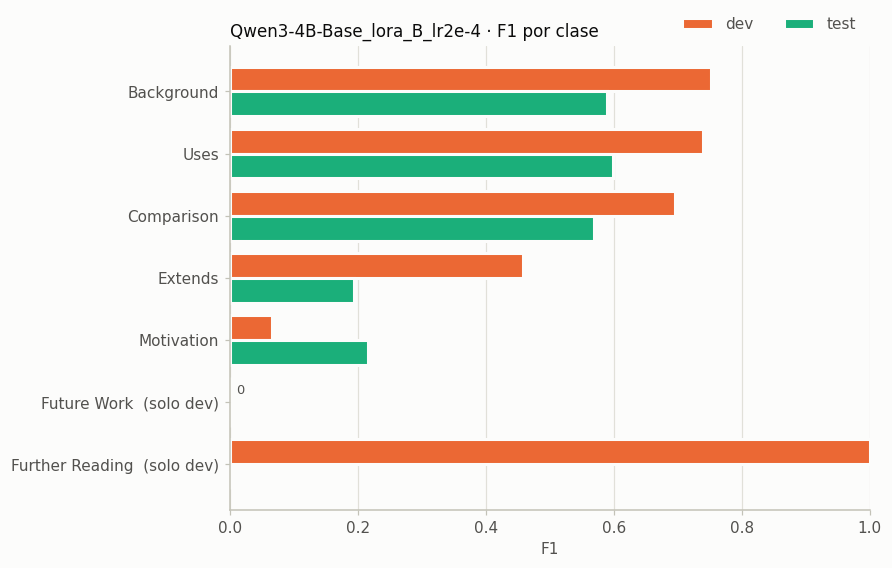

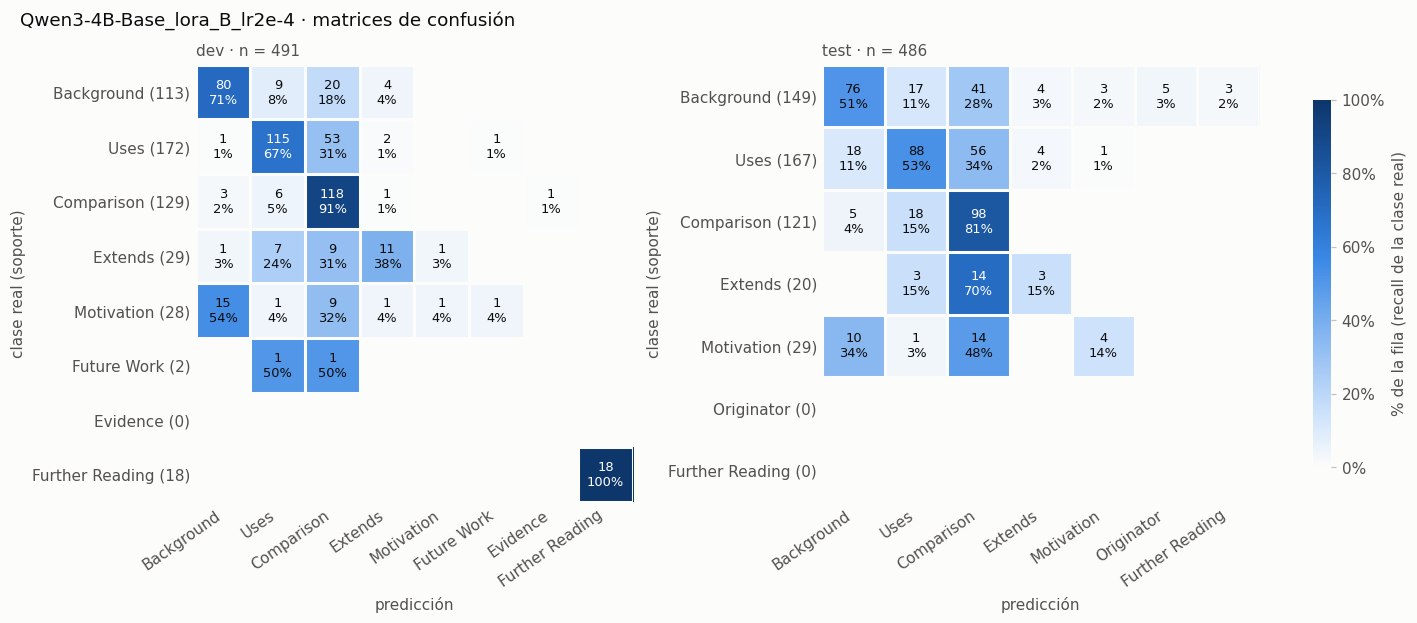

### Qwen3-4B-Base_lora_B_lr5e-5

,valor
modelo,Qwen/Qwen3-4B-Base
variante LoRA,lora
configuración,B
lr,5e-05
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,6.0
pasos entrenados / planeados,1128 / 1128
parada temprana,no


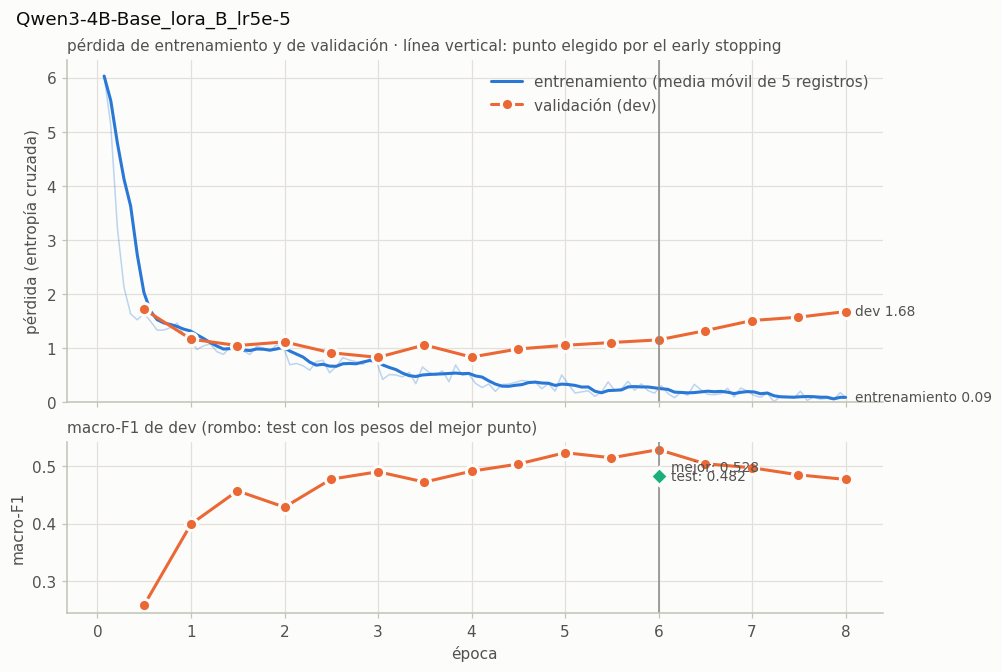

,dev,test
macro-F1 (clases de cada split),0.528,0.482
IC95 inferior,0.492,0.429
IC95 superior,0.641,0.533
macro-F1 (las 5 clases comunes),0.540,0.482
macro-F1 solo multicite,0.450,0.482
accuracy,0.660,0.578
ECE,0.187,0.256
n,491,486
clases evaluadas,7,5


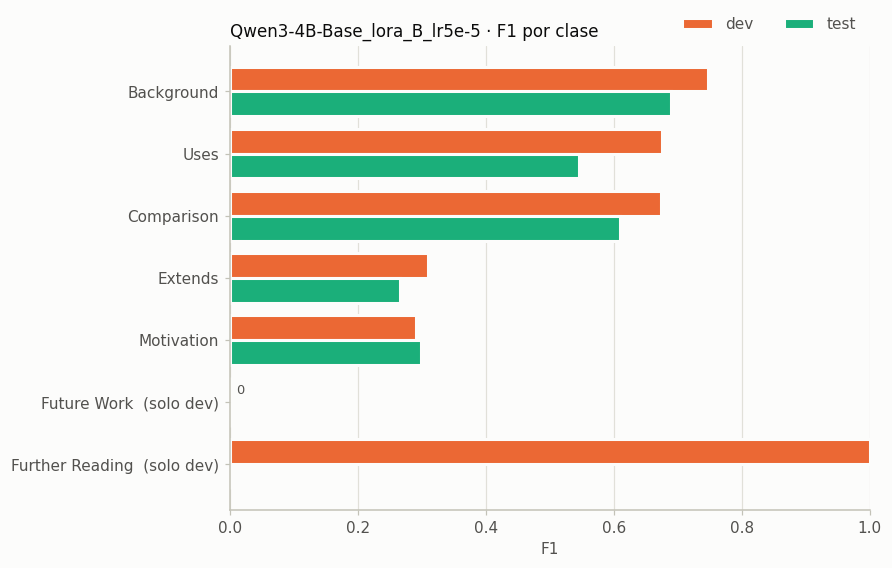

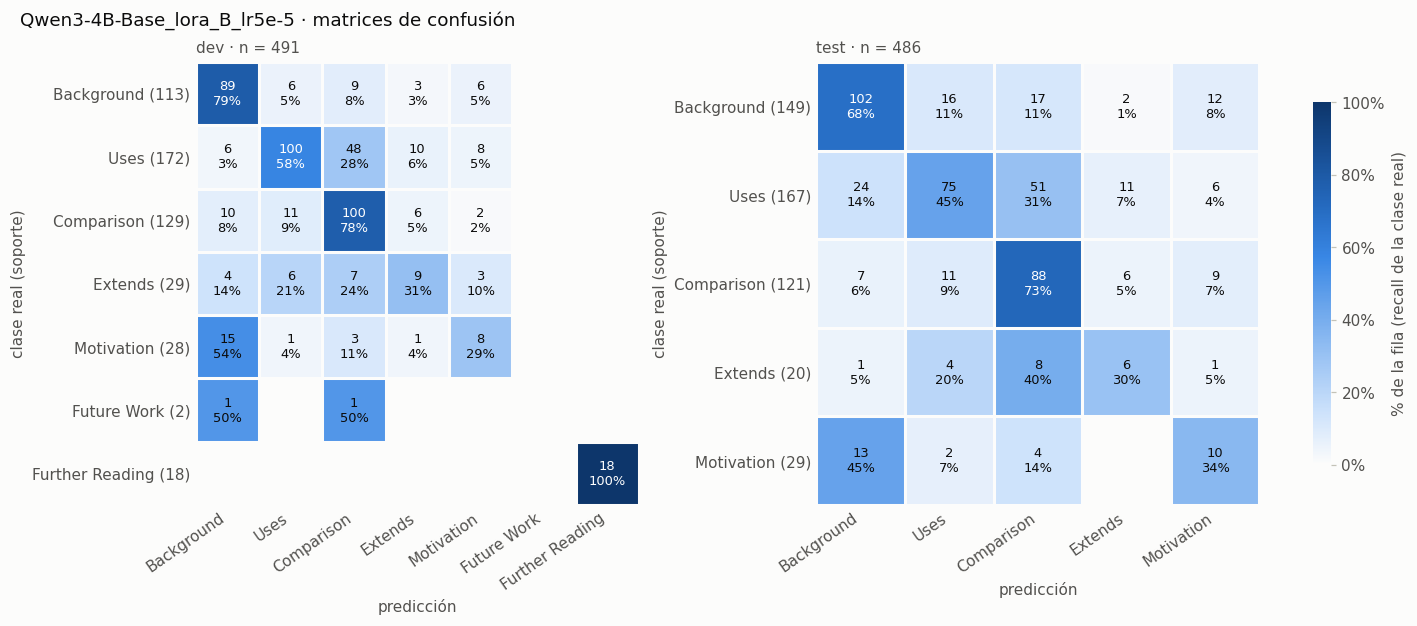

### Qwen3-8B-Base_lora_A_lr1e-4

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,A
lr,0.0001
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,2.0
pasos entrenados / planeados,634 / 1128
parada temprana,sí


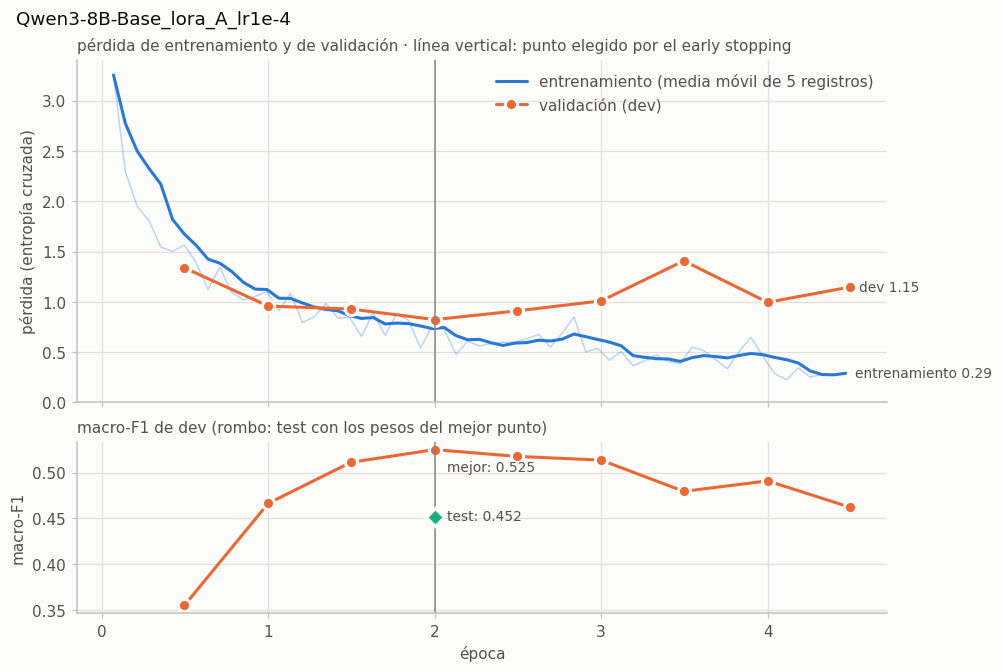

,dev,test
macro-F1 (clases de cada split),0.525,0.452
IC95 inferior,0.483,0.401
IC95 superior,0.631,0.508
macro-F1 (las 5 clases comunes),0.541,0.452
macro-F1 solo multicite,0.450,0.452
accuracy,0.715,0.638
ECE,0.057,0.099
n,491,486
clases evaluadas,7,5


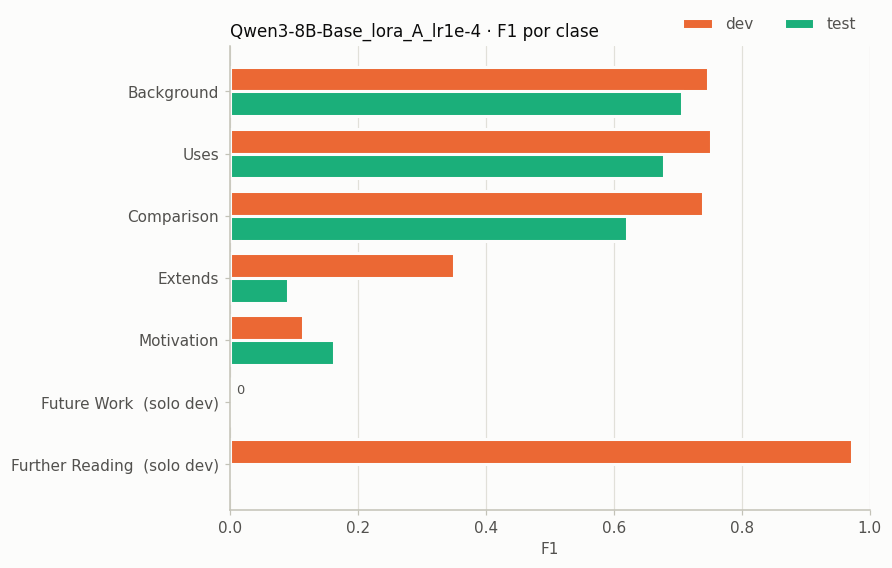

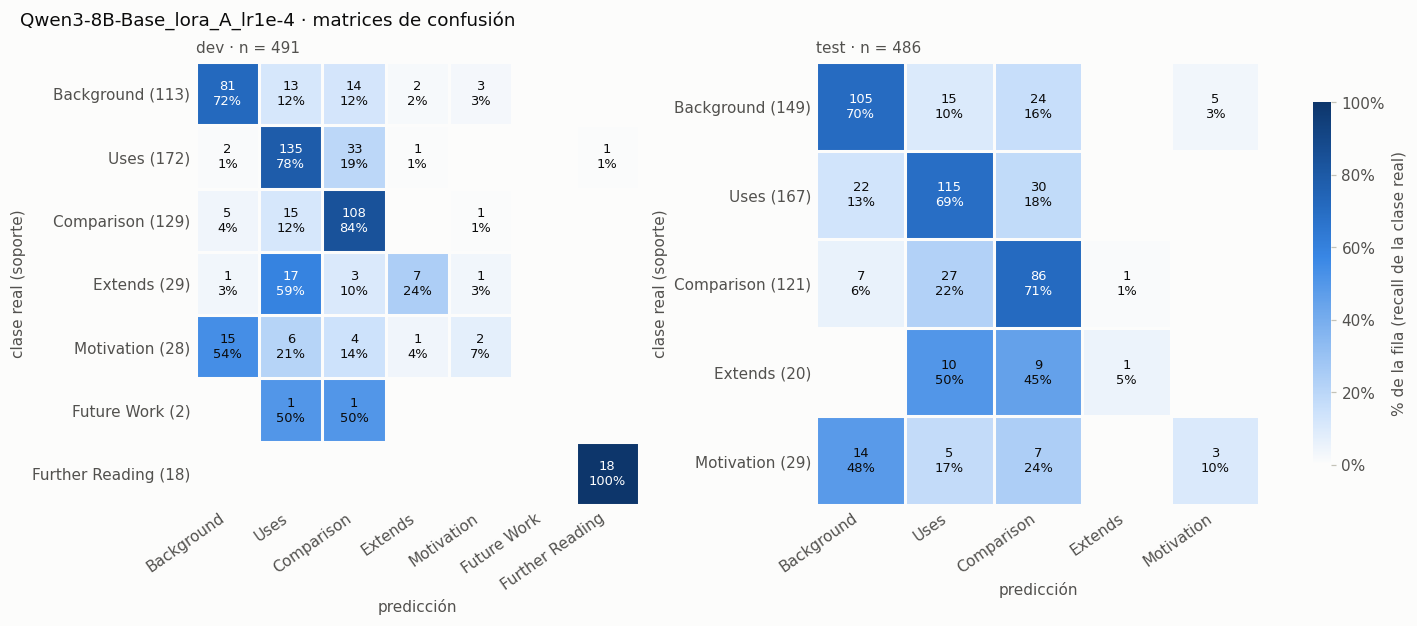

### Qwen3-8B-Base_lora_A_lr2e-4

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,A
lr,0.0002
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,2.0
pasos entrenados / planeados,634 / 1128
parada temprana,sí


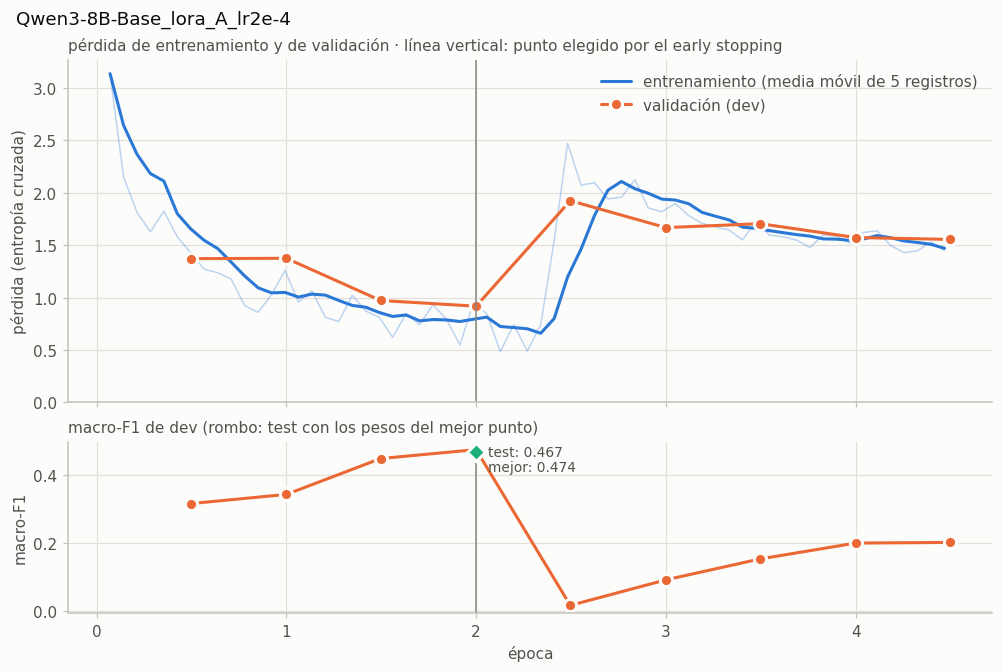

,dev,test
macro-F1 (clases de cada split),0.474,0.467
IC95 inferior,0.444,0.402
IC95 superior,0.566,0.526
macro-F1 (las 5 clases comunes),0.463,0.467
macro-F1 solo multicite,0.386,0.467
accuracy,0.668,0.619
ECE,0.063,0.094
n,491,486
clases evaluadas,7,5


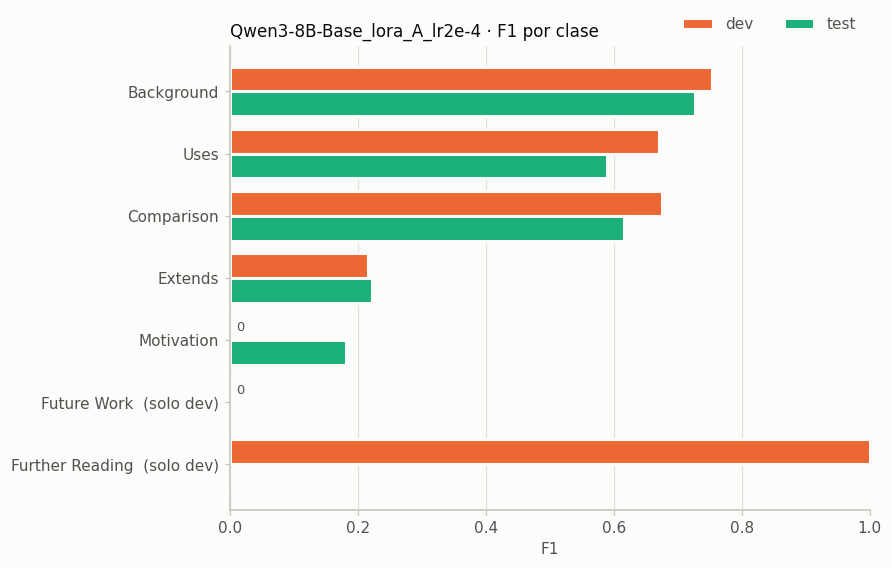

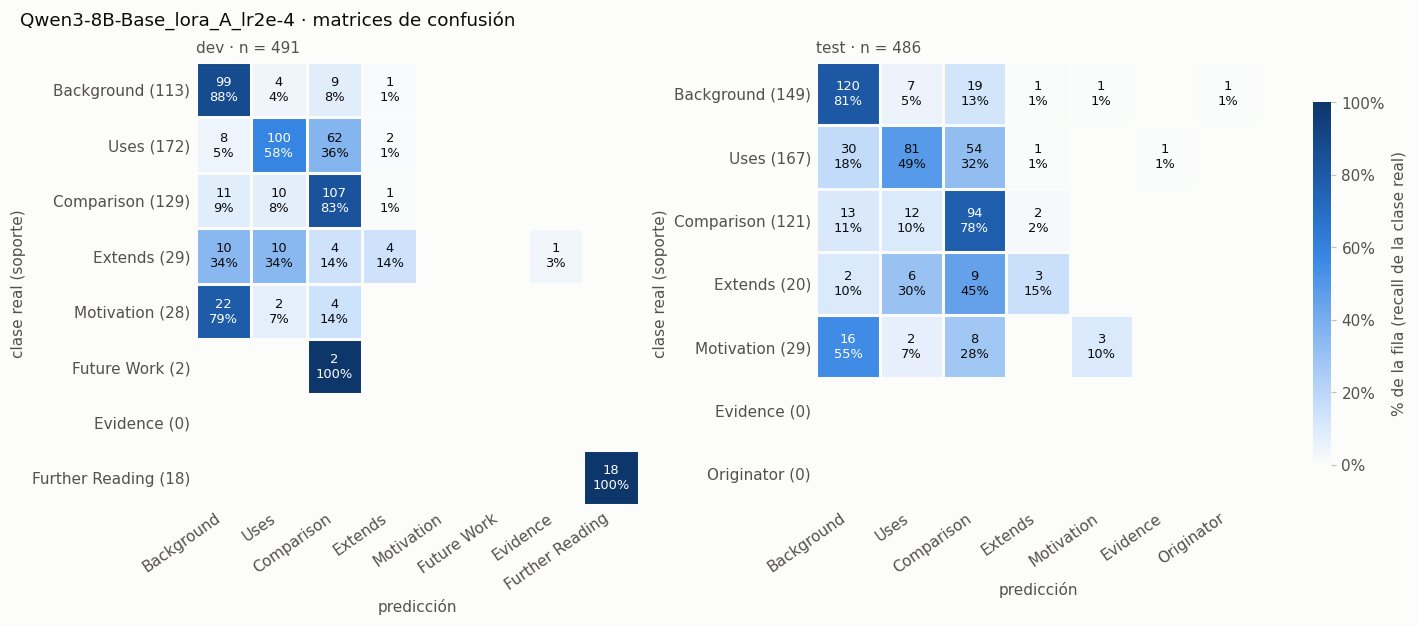

### Qwen3-8B-Base_lora_A_lr5e-5

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,A
lr,5e-05
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,2.0
pasos entrenados / planeados,634 / 1128
parada temprana,sí


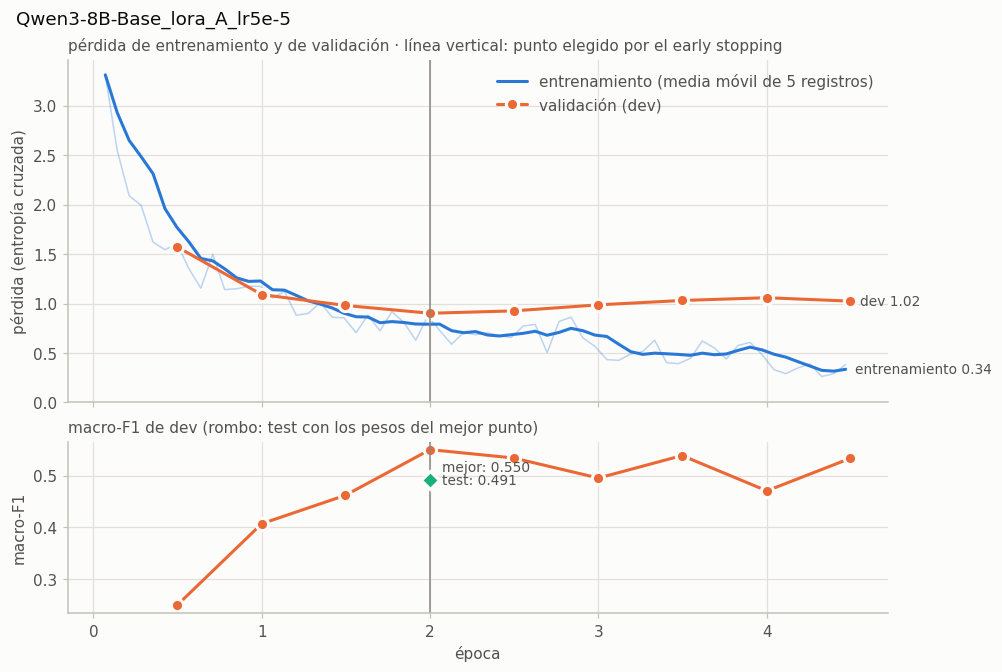

,dev,test
macro-F1 (clases de cada split),0.550,0.491
IC95 inferior,0.506,0.428
IC95 superior,0.658,0.553
macro-F1 (las 5 clases comunes),0.570,0.491
macro-F1 solo multicite,0.475,0.491
accuracy,0.709,0.636
ECE,0.079,0.068
n,491,486
clases evaluadas,7,5


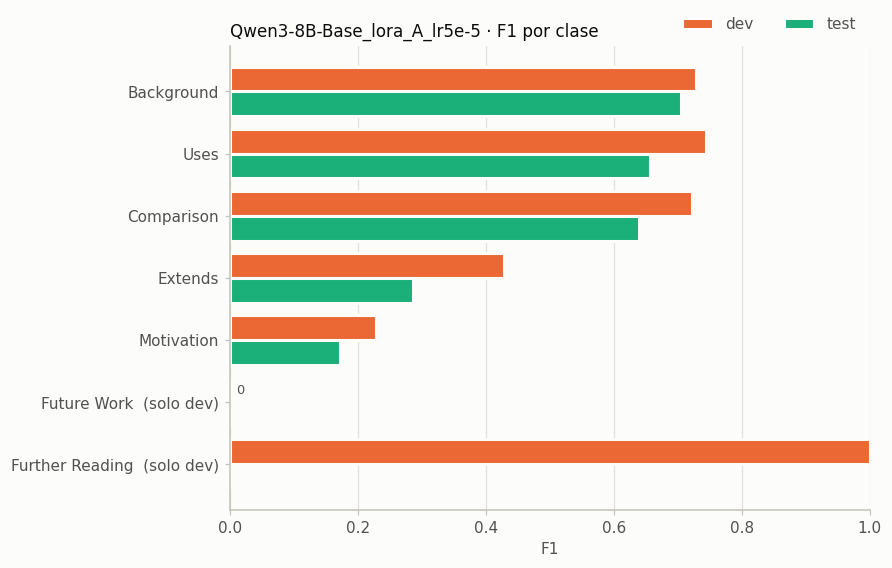

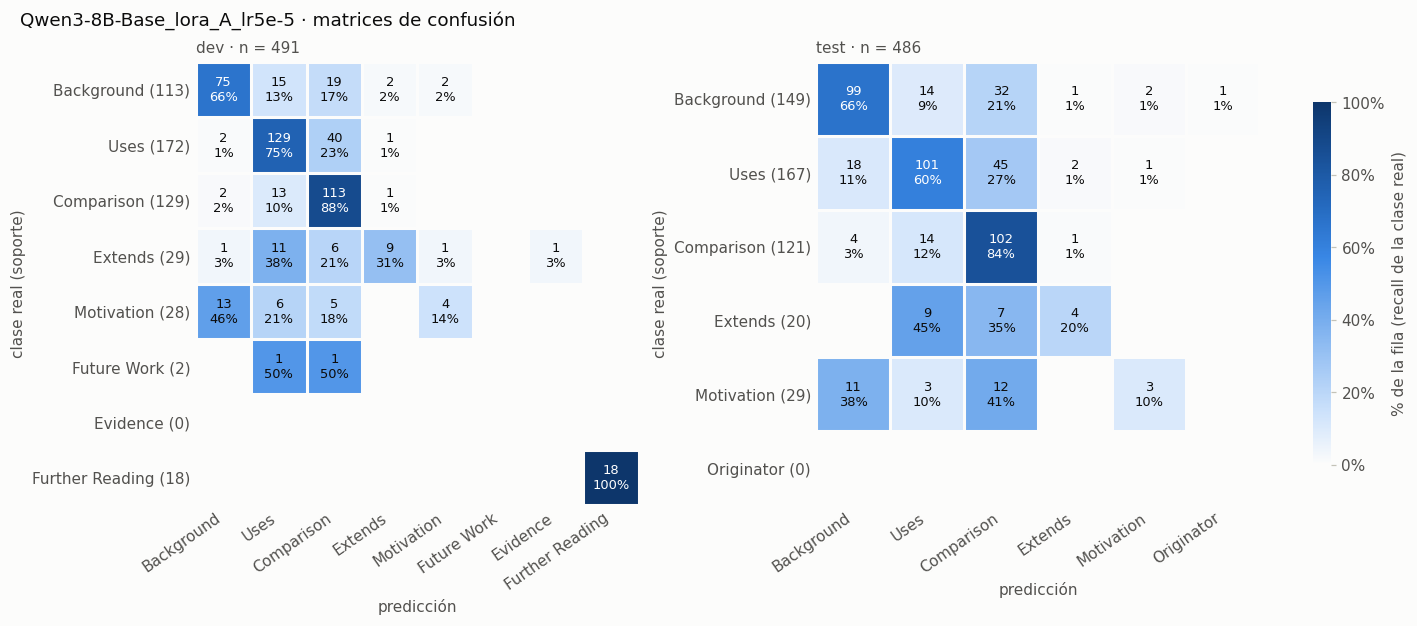

### Qwen3-8B-Base_lora_B_lr1e-4

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0001
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,3.0
pasos entrenados / planeados,775 / 1128
parada temprana,sí


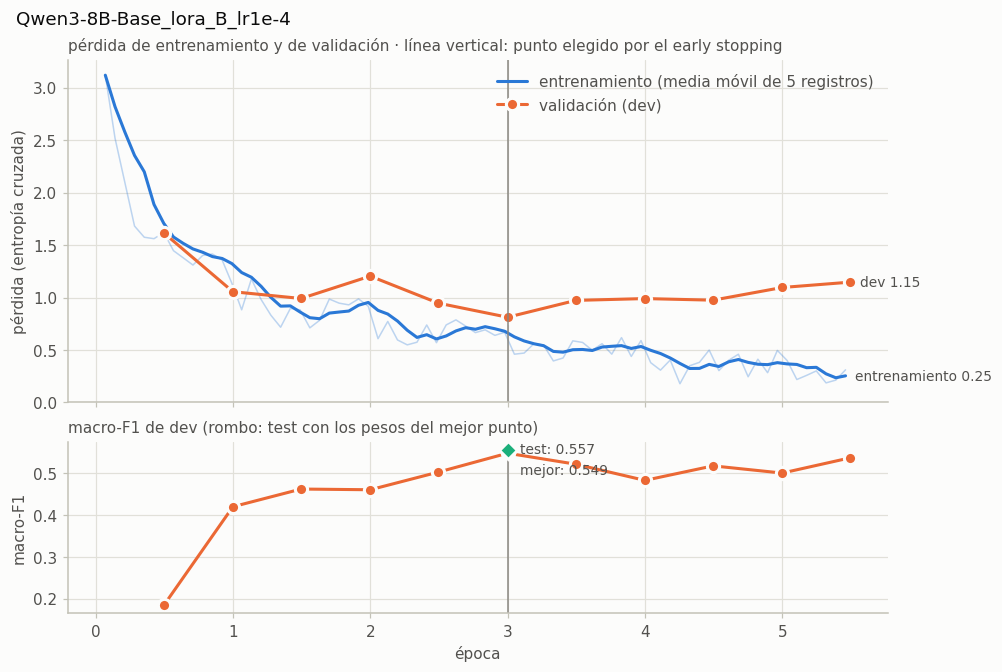

,dev,test
macro-F1 (clases de cada split),0.549,0.557
IC95 inferior,0.508,0.489
IC95 superior,0.664,0.621
macro-F1 (las 5 clases comunes),0.568,0.557
macro-F1 solo multicite,0.473,0.557
accuracy,0.723,0.663
ECE,0.074,0.072
n,491,486
clases evaluadas,7,5


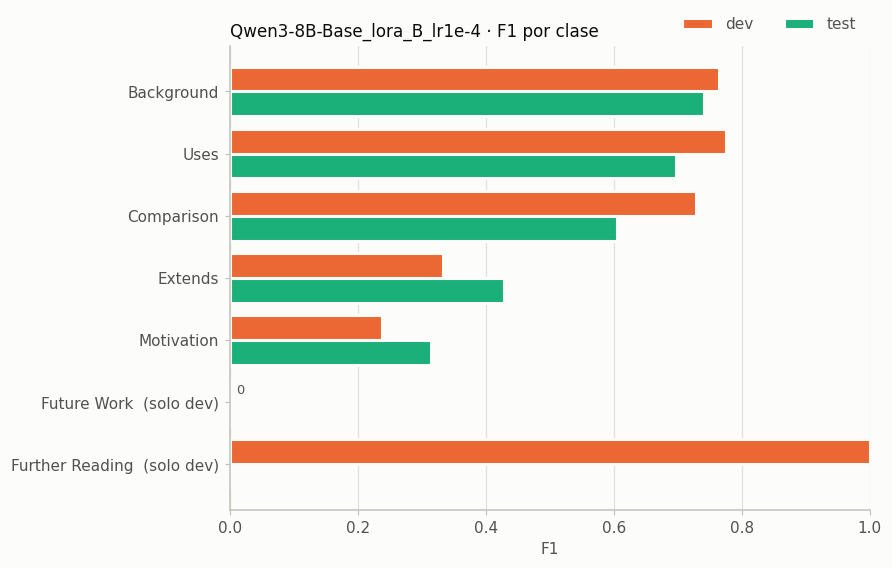

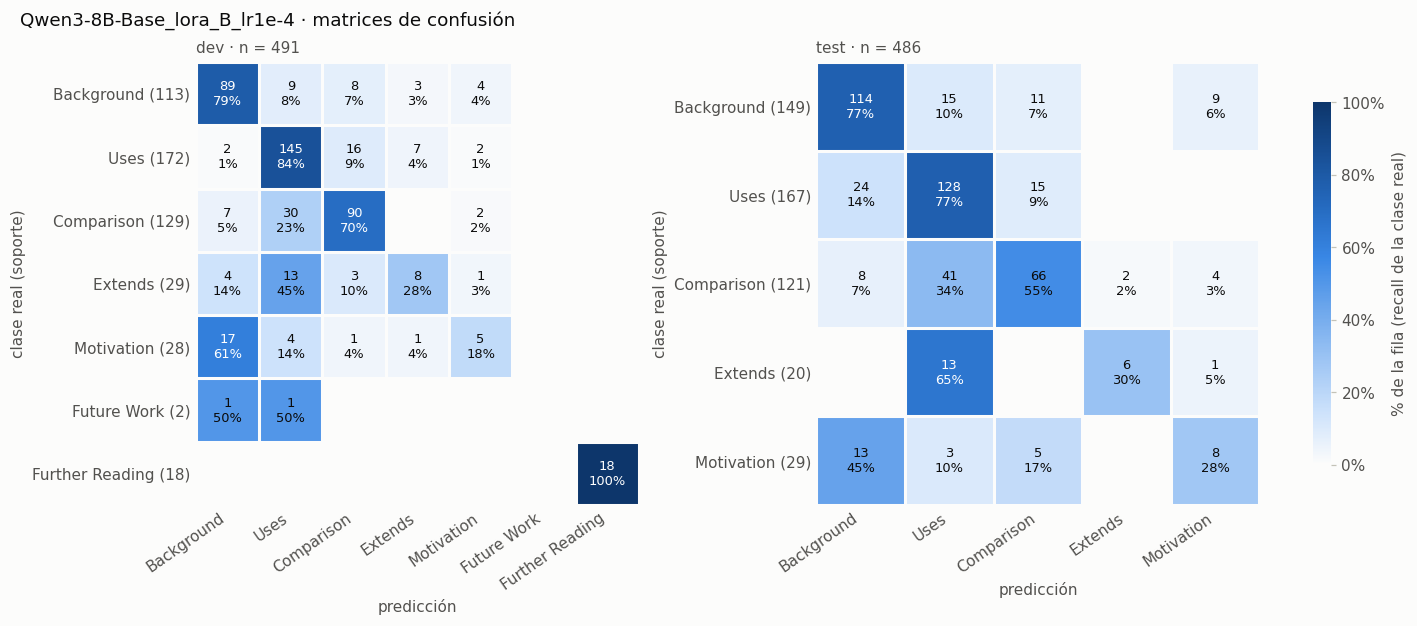

### Qwen3-8B-Base_lora_B_lr2e-4

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,0.0002
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,4.5
pasos entrenados / planeados,987 / 1128
parada temprana,sí


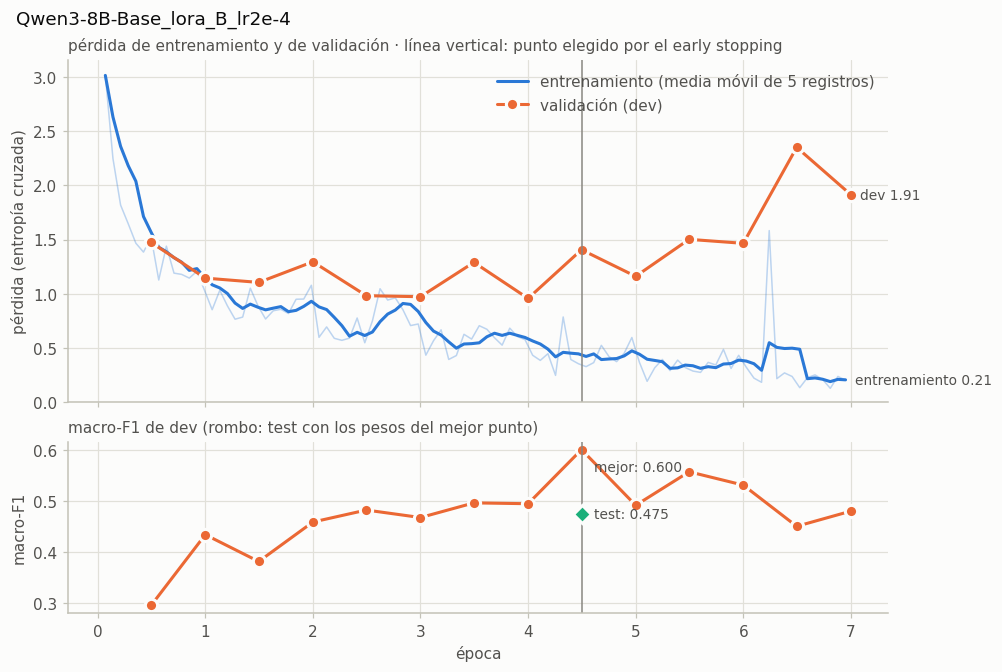

,dev,test
macro-F1 (clases de cada split),0.600,0.475
IC95 inferior,0.484,0.423
IC95 superior,0.669,0.528
macro-F1 (las 5 clases comunes),0.513,0.475
macro-F1 solo multicite,0.538,0.475
accuracy,0.664,0.568
ECE,0.170,0.239
n,491,486
clases evaluadas,7,5


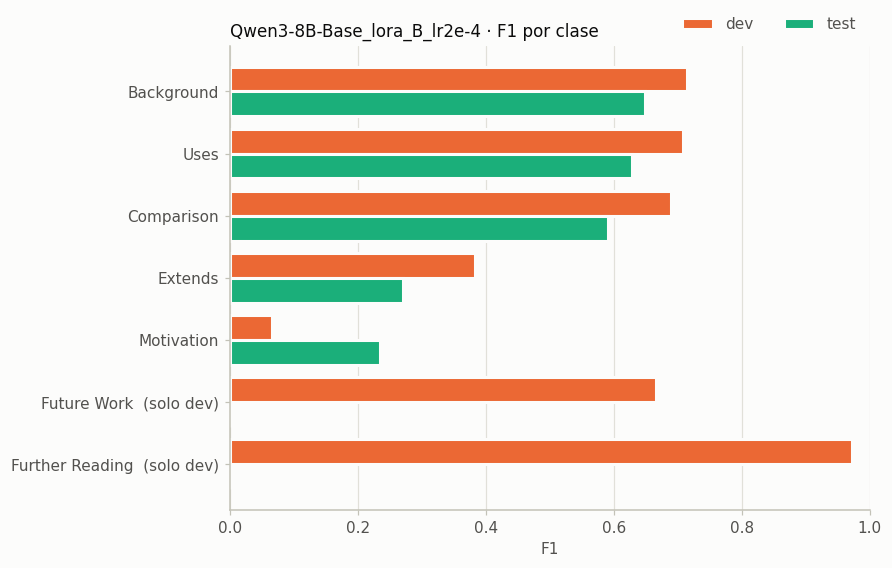

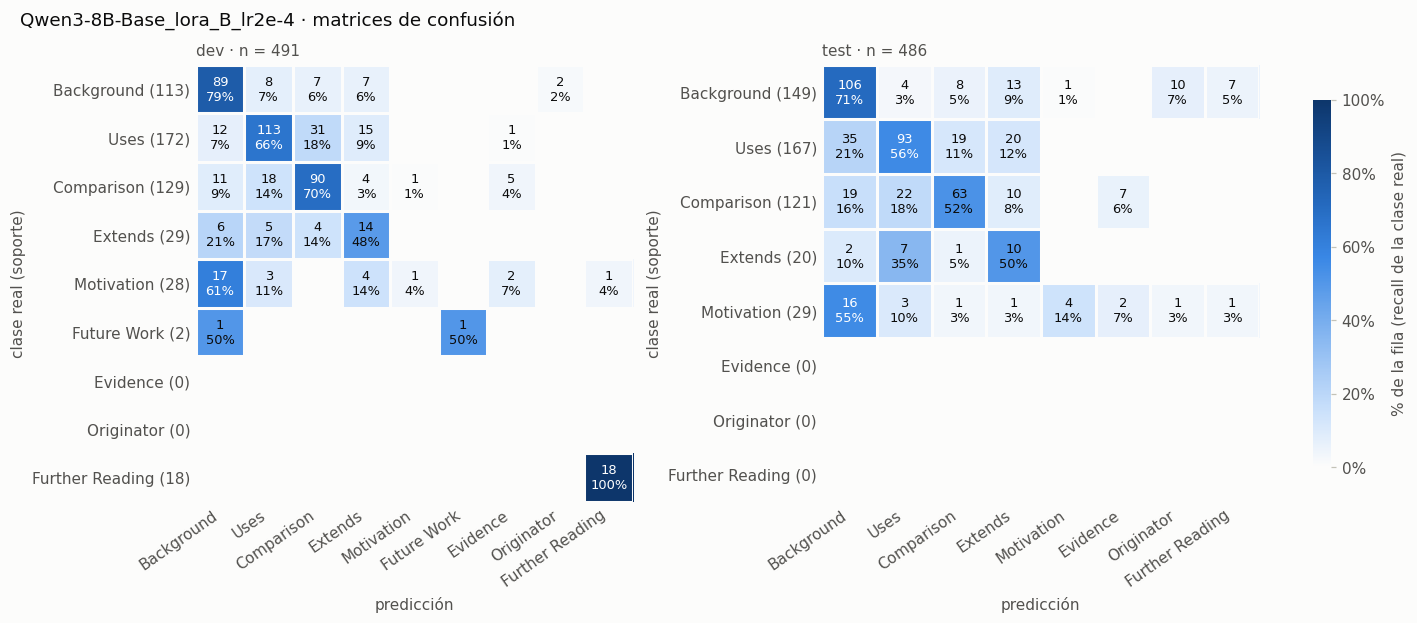

### Qwen3-8B-Base_lora_B_lr5e-5

,valor
modelo,Qwen/Qwen3-8B-Base
variante LoRA,lora
configuración,B
lr,5e-05
scheduler,wsd
épocas planeadas,8
lote efectivo,16
época del mejor macro-F1 dev,6.0
pasos entrenados / planeados,1128 / 1128
parada temprana,no


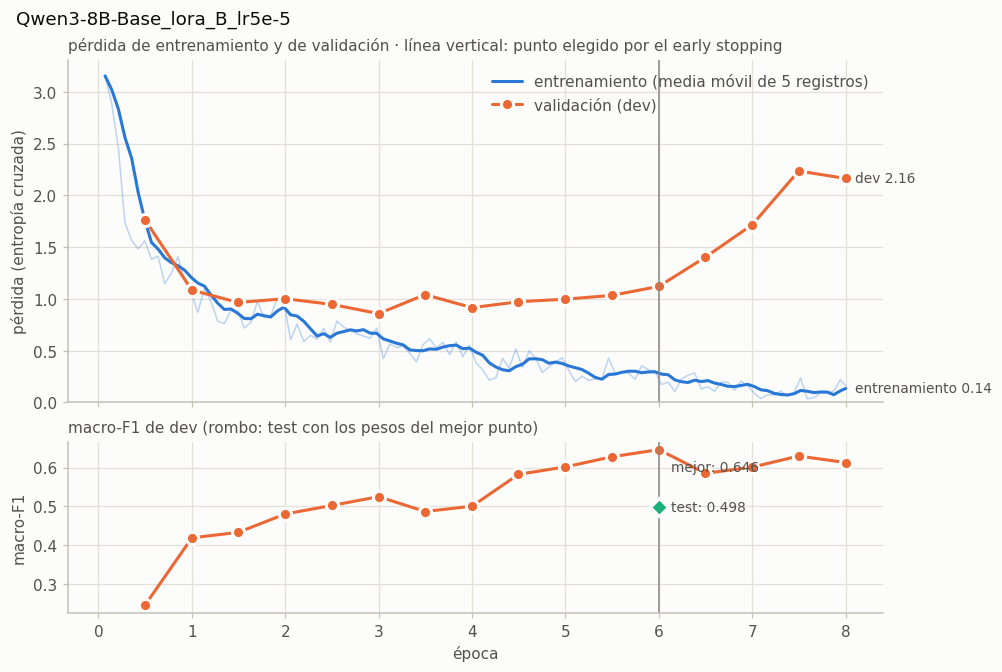

,dev,test
macro-F1 (clases de cada split),0.646,0.498
IC95 inferior,0.530,0.442
IC95 superior,0.717,0.551
macro-F1 (las 5 clases comunes),0.571,0.498
macro-F1 solo multicite,0.587,0.498
accuracy,0.709,0.611
ECE,0.159,0.238
n,491,486
clases evaluadas,7,5


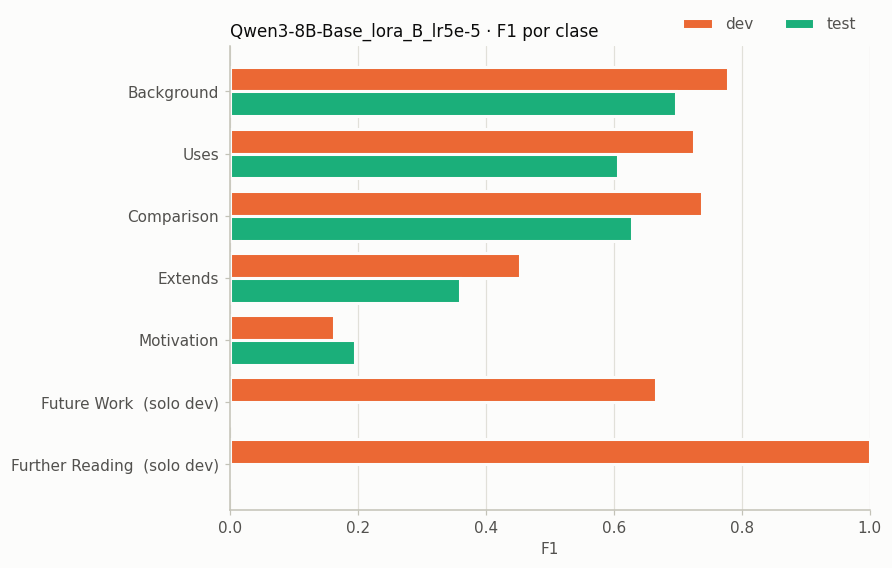

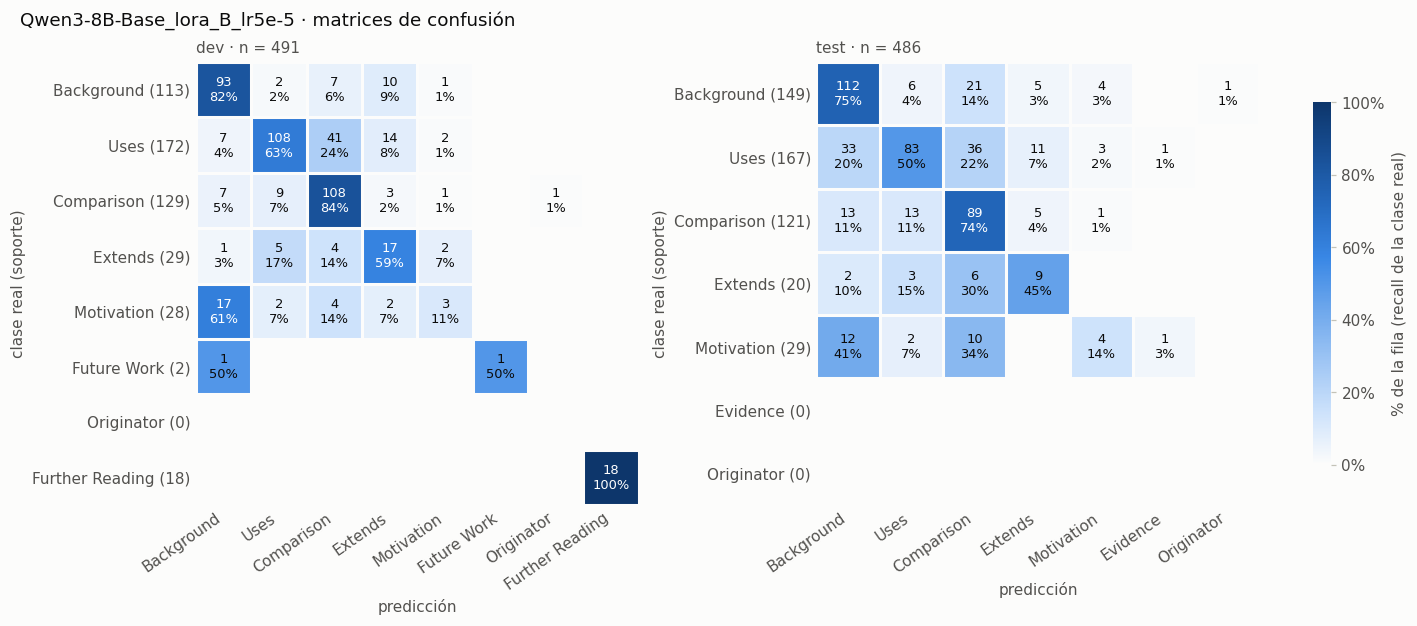

In [7]:
# @title 6 · Análisis de cada corrida
for c in corridas:
    display(Markdown(f"### {c['titulo']}"))
    mostrar(tabla_resumen(c), f"{c['titulo']} · resumen")
    graficar_perdidas(c)
    mostrar(tabla_dev_test(c), f"{c['titulo']} · métricas de dev y test")
    por_clase = tabla_por_clase(c)
    mostrar(por_clase, f"{c['titulo']} · métricas por clase")
    graficar_f1_por_clase(c, por_clase)
    graficar_confusiones(c)

## Todas las corridas

Para elegir modelo, variante o tasa, usa las columnas de dev: test se mira solo para reportar el resultado final, porque elegir con test lo convierte en otro conjunto de validación.

,modelo,config,variante,lr,mejor época,macro-F1 dev,macro-F1 dev (comunes),macro-F1 test,IC95 test inf.,IC95 test sup.,macro-F1 test (comunes),accuracy test
nombre_corrida,,,,,,,,,,,,
Qwen3-4B-Base_lora_A_lr5e-5,Qwen3-4B-Base,A,lora,5e-05,5.0,0.521215,0.529702,0.450258,0.400058,0.497532,0.450258,0.615226
Qwen3-4B-Base_lora_A_lr1e-4,Qwen3-4B-Base,A,lora,1e-04,4.0,0.572454,0.501435,0.428540,0.384445,0.471671,0.428540,0.613169
Qwen3-4B-Base_lora_A_lr2e-4,Qwen3-4B-Base,A,lora,2e-04,3.0,0.515549,0.521768,0.487804,0.436178,0.532922,0.487804,0.654321
Qwen3-4B-Base_lora_B_lr5e-5,Qwen3-4B-Base,B,lora,5e-05,6.0,0.528318,0.539646,0.481763,0.429279,0.532767,0.481763,0.578189
Qwen3-4B-Base_lora_B_lr1e-4,Qwen3-4B-Base,B,lora,1e-04,4.0,0.552032,0.572845,0.522624,0.464506,0.576700,0.522624,0.596708
Qwen3-4B-Base_lora_B_lr2e-4,Qwen3-4B-Base,B,lora,2e-04,4.5,0.530270,0.542378,0.433464,0.373231,0.492542,0.433464,0.553498
Qwen3-8B-Base_lora_A_lr5e-5,Qwen3-8B-Base,A,lora,5e-05,2.0,0.550123,0.570172,0.491422,0.428343,0.552780,0.491422,0.635802
Qwen3-8B-Base_lora_A_lr1e-4,Qwen3-8B-Base,A,lora,1e-04,2.0,0.525088,0.540529,0.451909,0.400682,0.508236,0.451909,0.637860
Qwen3-8B-Base_lora_A_lr2e-4,Qwen3-8B-Base,A,lora,2e-04,2.0,0.473613,0.463058,0.467359,0.402020,0.525529,0.467359,0.619342


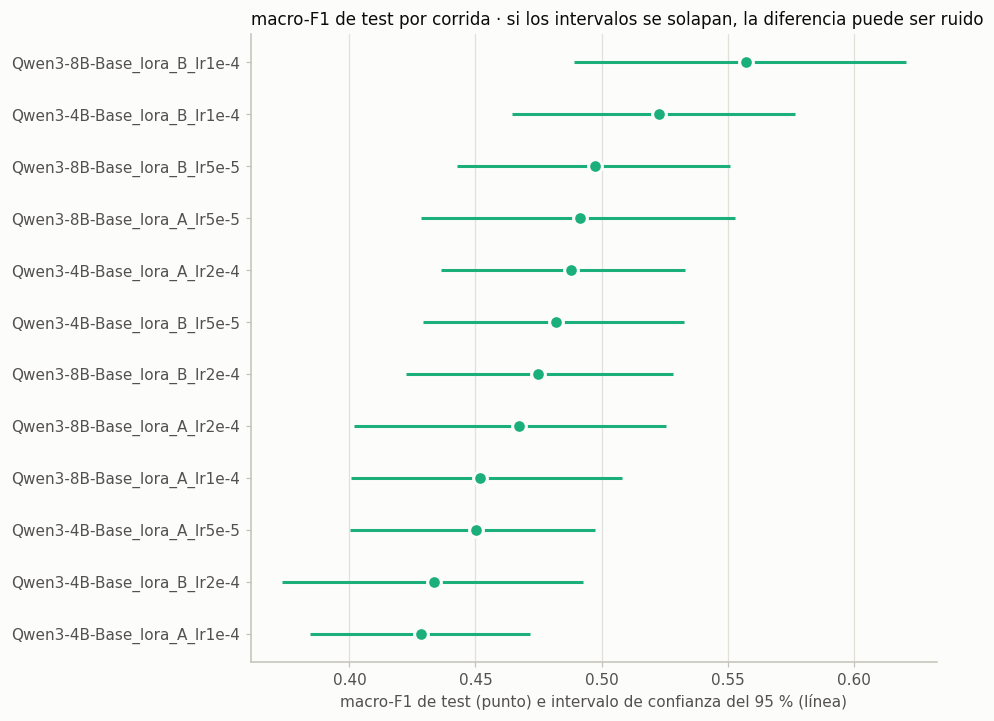

In [8]:
# @title 7 · Comparación entre corridas
def tabla_corridas(corridas: list[dict]) -> pd.DataFrame:
    """Una fila por corrida con su configuración y sus métricas principales de dev y test."""
    filas = {}
    for c in corridas:
        cfg, sel = c["config"], c["resumen"].get("seleccion", {})
        dev, test = c.get("metricas_dev") or {}, c.get("metricas_test") or {}
        f1_dev_c, f1_test_c, _ = macro_f1_comunes(c)
        spe = pasos_por_epoca(c)
        ic = test.get("macro_f1_ic95") or [None, None]
        filas[c["nombre"]] = {
            "modelo": cfg.get("modelo", "").split("/")[-1], "config": cfg.get("configuracion"),
            "variante": cfg.get("lora_tipo"), "lr": cfg.get("lr"),
            "mejor época": round(sel["mejor_paso"] / spe, 1) if spe and sel.get("mejor_paso") else None,
            "macro-F1 dev": dev.get("macro_f1"), "macro-F1 dev (comunes)": f1_dev_c,
            "macro-F1 test": test.get("macro_f1"), "IC95 test inf.": ic[0], "IC95 test sup.": ic[1],
            "macro-F1 test (comunes)": f1_test_c, "accuracy test": test.get("accuracy"),
        }
    tabla = pd.DataFrame(filas).T.rename_axis("nombre_corrida")
    for columna in tabla.columns.drop(["modelo", "config", "variante"]):
        tabla[columna] = pd.to_numeric(tabla[columna], errors="coerce")
    return tabla


comparacion = tabla_corridas(corridas)
mostrar(comparacion.sort_values(["modelo", "config", "variante", "lr"]), "Todas las corridas",
        formatos={"lr": "{:.0e}", "mejor época": "{:.1f}"})
graficar_test_con_ic(comparacion)

## Ranking en test

In [9]:
# @title 8 · Ranking por macro-F1 de test
ranking = (comparacion["macro-F1 test"].dropna().astype(float).sort_values(ascending=False)
           .rename("f1_macro").rename_axis("nombre_corrida").reset_index())
ranking.index = range(1, len(ranking) + 1)
if GUARDAR:
    (CARPETA_RESULTADOS / "analisis").mkdir(exist_ok=True)
    comparacion.to_csv(CARPETA_RESULTADOS / "analisis" / "comparacion.csv")
    ranking.to_csv(CARPETA_RESULTADOS / "analisis" / "ranking_test.csv", index_label="puesto")
mostrar(ranking, "Ranking en test (macro-F1)", decimales=4)

,nombre_corrida,f1_macro
1,Qwen3-8B-Base_lora_B_lr1e-4,0.5571
2,Qwen3-4B-Base_lora_B_lr1e-4,0.5226
3,Qwen3-8B-Base_lora_B_lr5e-5,0.4976
4,Qwen3-8B-Base_lora_A_lr5e-5,0.4914
5,Qwen3-4B-Base_lora_A_lr2e-4,0.4878
6,Qwen3-4B-Base_lora_B_lr5e-5,0.4818
7,Qwen3-8B-Base_lora_B_lr2e-4,0.4748
8,Qwen3-8B-Base_lora_A_lr2e-4,0.4674
9,Qwen3-8B-Base_lora_A_lr1e-4,0.4519
10,Qwen3-4B-Base_lora_A_lr5e-5,0.4503
